# Projet Smart - Groupe 4

Yanis BOUNCEUR · Gautier DREYER · Ange MAGATSING NGASSEU · Vladimir MAJCHER

## Sommaire : où trouver chaque attendu du livrable final

| Attendu du sujet | Où le trouver |
|---|---|
| Contexte, formalisation des données et du problème | Livrable 1, parties 1 et 3 ; Livrable 2, partie 0.2 |
| Preuve de complexité (réduction, NP-difficulté) | Livrable 1, partie 2 |
| PLNE complète et corrigée | Livrable 1, parties 3 et 6 ; version corrigée implémentée : Livrable 2, partie 9 |
| Utilisation de l'approche exacte | Livrable 1, partie 4 ; Livrable 2, partie 9 (PLNE contre GRASP + Tabou) |
| Métaheuristique formalisée : solutions, voisinage, opérateurs, guidage | Livrable 2, partie 0 |
| Implémentation : étapes, mécanismes, critères d'arrêt | Livrable 2, parties 1 à 3 |
| Cas de test et démonstration sur plusieurs instances | Livrable 2, parties 2, 9 et 10 |
| Plan d'expérience (taille, répartition des clients, fenêtres de temps) | Livrable 2, parties 4 et 5 |
| Validation VRPLIB et gap | Livrable 2, partie 4 |
| Analyse : qualité, temps de calcul, robustesse, sensibilité, statistiques | Livrable 2, parties 5 à 8 |
| Limites et axes d'amélioration | Livrable 2, partie 11 |
| Déroulement du projet (storytelling), planning prévu et réel, comparatif des 3 métaheuristiques | partie 12 |
| Références bibliographiques | fin du notebook |

# Livrable 1



Livrable: Modélisation graphique et stratégie d’optimisation
Optimisation des tournées de livraison – Task Force CesiCDP ADEME

Ce document présente le problème d’optimisation des tournées de livraison, sa modélisation sous forme de graphe, sa complexité théorique, son modèle mathématique et la stratégie de résolution retenue. Il est rédigé pour qu’un lecteur qui découvre le sujet puisse suivre chaque étape.

## 1. Présentation du problème et modélisation graphique
### 1.1. Le contexte de la mission
L’ADEME (Agence de la transition écologique) cherche à optimiser les tournées de livraison urbaines afin de réduire la durée globale des trajets, l’empreinte carbone (CO2) et les coûts opérationnels.

Le problème étudié est le **CVRPTW** (*Capacitated Vehicle Routing Problem with Time Windows*) : un problème de tournées de véhicules avec capacité, dans lequel chaque client doit être livré dans une **fenêtre horaire** imposée.

### 1.2. Représentation sous forme de graphe
Pour traiter ce problème par ordinateur, on modélise le réseau routier par un **graphe complet pondéré** (orienté ou non) $G = (V, A)$.

**Les sommets (V)**
- Le sommet 0 représente l’entrepôt (dépôt central) d’où partent et où reviennent tous les véhicules.
- Les sommets 1, 2, …, n représentent les clients à livrer.

**Les arcs (A)**
- Ils représentent les liaisons entre les lieux. Chaque arc $(i, j)$ porte un poids $c_{ij}$ : la durée de trajet ou la distance entre le lieu $i$ et le lieu $j$.

**Les contraintes métier**
- **Flotte de véhicules :** $k$ véhicules identiques, tous positionnés au dépôt au départ.
- **Capacité (Q) :** chaque camion a une capacité maximale $Q$ qu’il ne peut pas dépasser.
- **Demande ($q_i$) :** chaque client $i$ demande une quantité de marchandises $q_i$.

**Pour avoir A**

- **Fenêtre de temps $[a_i, b_i]$ :** la livraison chez le client $i$ doit commencer entre $a_i$ (ouverture) et $b_i$ (fermeture). Livrer hors fenêtre est interdit.
- **Attente autorisée :** un camion arrivé trop tôt attend l'ouverture de la fenêtre.
- **Temps de service $s_i$ :** durée de la livraison chez le client $i$.
- **Trafic :** la durée des trajets dépend de la tranche horaire. Ce point sera intégré dans la métaheuristique, avec des durées $c_{ij}$ qui dépendent de l'heure de départ.



**Exemple d’instance**

Pour fixer les idées, la figure 1 montre une petite instance : un dépôt (sommet 0) et 6 clients. Chaque client est annoté de sa demande $q$ et de sa fenêtre de temps $[a, b]$ en minutes. Les traits gris sont les arcs du graphe complet : chacun correspond à une durée de trajet (les valeurs sont données dans la matrice de la section 5). Les camions ont une capacité Q = 12 et la flotte compte K = 2 véhicules.

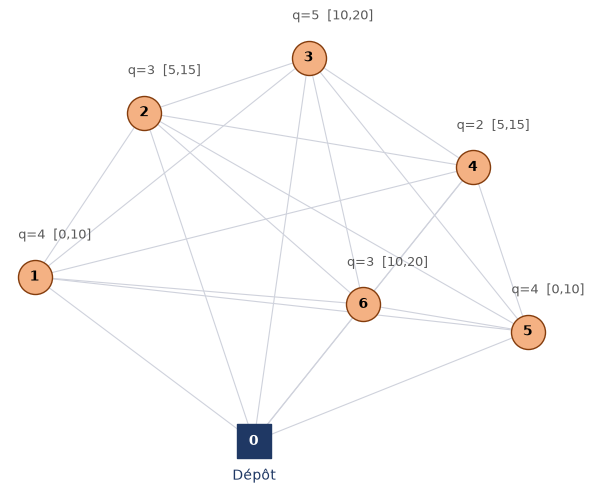

In [5]:
import matplotlib.pyplot as plt
pos={0:(0,0),1:(-4,3),2:(-2,6),3:(1,7),4:(4,5),5:(5,2),6:(2,2.5)}
q={1:4,2:3,3:5,4:2,5:4,6:3}
tw={1:(0,10),2:(5,15),3:(10,20),4:(5,15),5:(0,10),6:(10,20)}  # fenêtres [a, b] en minutes
def graphe(tournees=None):
    fig,ax=plt.subplots(figsize=(7,6))
    for i in pos:
        for j in pos:
            if i<j: ax.plot(*zip(pos[i],pos[j]),color='#cfd2dc',lw=0.8,zorder=1)
    if tournees:
        for t,col in tournees:
            for a,b in zip(t,t[1:]):
                (x1,y1),(x2,y2)=pos[a],pos[b]
                ax.annotate('',xy=(x2,y2),xytext=(x1,y1),arrowprops=dict(arrowstyle='-|>',color=col,lw=2,shrinkA=12,shrinkB=12),zorder=2)
                d=((x1-x2)**2+(y1-y2)**2)**.5
                ax.text((x1+x2)/2,(y1+y2)/2,f'{d:.1f}',color=col,fontweight='bold',fontsize=9)
    ax.scatter(*pos[0],marker='s',s=600,color='#1f3864',zorder=3)
    ax.text(*pos[0],'0',color='white',ha='center',va='center',fontweight='bold',zorder=4)
    ax.text(pos[0][0],pos[0][1]-0.7,'Dépôt',ha='center',color='#1f3864')
    for i in q:
        ax.scatter(*pos[i],s=600,color='#f4b183',edgecolors='#843c0c',zorder=3)
        ax.text(*pos[i],str(i),ha='center',va='center',fontweight='bold',zorder=4)
        ax.text(pos[i][0]-0.3,pos[i][1]+0.7,f'q={q[i]}  [{tw[i][0]},{tw[i][1]}]',color='#595959',fontsize=9)
    if tournees:
        for t,col in tournees: ax.plot([],[],color=col,lw=2,label=t[2] if False else '')
        ax.legend(['Tournée 1 : 0 → 1 → 2 → 3 → 0','Tournée 2 : 0 → 5 → 4 → 6 → 0'],loc='lower center',bbox_to_anchor=(0.5,-0.15),frameon=False)
    ax.axis('off'); ax.set_aspect('equal'); plt.show()
graphe()

*Figure 1 – Graphe complet d’une instance à 6 clients (sommets, demandes, arcs)*

## 2. Classification et complexité théorique
### 2.1. À quelle classe appartient ce problème ?
Le problème est **NP-difficile** dans sa version d'optimisation et **NP-complet** dans sa version de décision.

**Version de décision (oui / non) : NP-complet**

*Question :* existe-t-il un ensemble de tournées respectant la capacité des camions et les fenêtres de temps, dont la durée totale est inférieure ou égale à T minutes ?
- **Appartenance à NP :** si quelqu'un nous fournit une solution (un « certificat »), on vérifie sa validité en temps polynomial, de l'ordre de O(n) : chaque client est visité une seule fois, les capacités sont respectées, les heures de livraison tombent dans les fenêtres et la durée est inférieure ou égale à T.
- **NP-difficulté : réduction polynomiale depuis le TSP.** Le TSP est NP-complet (par réduction depuis le cycle hamiltonien, Karp 1972). À partir d'une instance du TSP ($n$ villes, distances $d$, borne $T$), on construit en $O(n^2)$ :
  - dépôt = ville 1, clients = les autres villes, $c_{ij} = d_{ij}$ ;
  - $K = 1$ camion, $q_i = 1$, $Q = n$ ;
  - fenêtres sans effet : $a_i = 0$, $b_i = +\infty$, $s_i = 0$.

  Une tournée unique qui visite tous les clients et revient au dépôt est exactement un cycle hamiltonien de même durée. Il existe donc un tour $\le T$ **si et seulement si** il existe une tournée $\le T$. Le CVRPTW est donc NP-complet.
- **Les fenêtres de temps durcissent encore le problème :** avec des fenêtres, trouver une simple solution réalisable est déjà NP-complet (Savelsbergh, 1985).

**Version d'optimisation : NP-difficile**

*Question :* quelle est la *meilleure* combinaison de tournées, celle qui minimise la durée totale ? Trouver la meilleure solution est au moins aussi difficile que de répondre à la version de décision.

### 2.2. L'explosion combinatoire
Pour n clients, le nombre de façons d'ordonner les visites et de les répartir entre les camions croît de manière factorielle, donc plus vite qu'une exponentielle.
- **10 clients :** déjà $10! \approx 3{,}6$ millions d'ordres de visite.
- **30 clients :** $30! \approx 2{,}7 \times 10^{32}$ combinaisons. Un ordinateur très puissant mettrait des milliards d'années à tout tester par force brute.

## 3. Modélisation mathématique (PLNE)
Pour exprimer le problème sous une forme exploitable par un solveur, on utilise la programmation linéaire en nombres entiers (PLNE). Le modèle repose sur trois composants : les variables de décision, la fonction objectif et les contraintes.

### 3.1. Les variables de décision
Ce sont les inconnues que le solveur doit déterminer.
1. Variable binaire de trajet (vaut 1 si le véhicule k va directement du lieu i au lieu j, avec $i \neq j$, 0 sinon) :
$$x_{ijk} \in \{0, 1\}$$
2. Variable de charge auxiliaire $u_i \geq 0$ : elle suit la charge cumulée du camion au fil de la tournée et permet d'éliminer les « sous-tours » (des boucles isolées qui ne passeraient pas par le dépôt).
3. Variable de temps $T_{ik} \geq 0$ : heure à laquelle le camion $k$ commence la livraison chez le client $i$.

### 3.2. La fonction objectif
L'objectif est de minimiser le temps total de parcours de l'ensemble de la flotte :
$$\min Z = \sum_{k=1}^{K} \sum_{i=0}^{n} \sum_{j=0}^{n} c_{ij} \cdot x_{ijk}$$
où $c_{ij}$ est le coût (la durée) du trajet entre i et j.

### 3.3. Les contraintes
Ce sont les règles que le modèle doit respecter.

**1. Visite unique de chaque client**

Chaque client j (hors dépôt) est visité exactement une fois, par un seul véhicule :
$$\sum_{k=1}^{K} \sum_{i=0, i\neq j}^{n} x_{ijk} = 1 \quad \forall j \in \{1, \dots, n\}$$

**2. Flux et continuité des tournées**

Si un camion k arrive chez un client j, il doit obligatoirement en repartir :
$$\sum_{i=0, i\neq j}^{n} x_{ijk} - \sum_{l=0, l\neq j}^{n} x_{jlk} = 0 \quad \forall j \in \{0, \dots, n\}, \forall k$$

**3. Capacité maximale du véhicule**

La somme des demandes $q_j$ des clients livrés par le camion k ne doit pas dépasser sa capacité Q :
$$\sum_{i=0}^{n} \sum_{j=1, j\neq i}^{n} q_j \cdot x_{ijk} \leq Q \quad \forall k \in \{1, \dots, K\}$$


**4. Élimination des sous-tours (MTZ adapté)**

Pour empêcher la formation de cycles fermés indépendants du dépôt :
$$u_i - u_j + Q \cdot x_{ijk} \leq Q - q_j \quad \forall i, j \neq 0, i \neq j, \forall k$$
$$q_i \leq u_i \leq Q \quad \forall i \in \{1, \dots, n\}$$

avec $x_{ijk}$ = 1 si le camion $k$ va directement de $i$ à $j$, $u_i$ la charge cumulée du camion à son arrivée chez $i$, $q_j$ la demande de $j$ et $Q$ la capacité.

**Pourquoi cette forme ?** Un solveur PLNE ne comprend pas « si $x_{ijk} = 1$ alors $u_j \geq u_i + q_j$ ». Le terme $Q \cdot x_{ijk}$ (formulation de Miller-Tucker-Zemlin) active ou désactive la contrainte :
- si $x_{ijk} = 1$, elle devient $u_j \geq u_i + q_j$ : la charge augmente le long de la tournée, donc aucun cycle ne peut se refermer sans repasser par le dépôt ;
- si $x_{ijk} = 0$, elle devient $u_i - u_j \leq Q - q_j$, toujours vraie puisque $u_i \leq Q$ et $u_j \geq q_j$.

**5. Départ du dépôt**

Chaque camion quitte le dépôt au plus une fois :
$$\sum_{j=1}^{n} x_{0jk} \leq 1 \quad \forall k$$

**6. Enchaînement des horaires**

Si le camion k va de i à j, la livraison en j commence au plus tôt après la fin de la livraison en i plus le temps de trajet :
$$T_{ik} + s_i + c_{ij} - T_{jk} \leq M\,(1 - x_{ijk}) \quad \forall i, j,\ i \neq j,\ j \neq 0,\ \forall k$$
M est un grand nombre : si $x_{ijk} = 0$, la contrainte est désactivée. L'inégalité autorise l'attente, car $T_{jk}$ peut être plus tard que l'heure d'arrivée.

**7. Fenêtres de temps**

La livraison chez le client i commence entre son ouverture $a_i$ et sa fermeture $b_i$ :
$$a_i \leq T_{ik} \leq b_i \quad \forall i,\ \forall k$$

## 4. Méthode proposée pour trouver la meilleure solution
Face à la complexité NP-difficile, nous adoptons une approche à deux niveaux, selon la taille de l’instance.

| Taille | Petite instance (n < 20) | Grande instance (n ≥ 20) |
|---|---|---|
| **Méthode** | Méthode exacte (PLNE avec solveur) | Métaheuristique (recherche locale, ALNS) |
| **Résultat** | Optimum absolu | Excellente solution, obtenue très vite |

### 4.1. Petites instances : méthode exacte (PLNE / PuLP)
- **Outil :** programmation linéaire en nombres entiers via un solveur (par exemple CBC avec PuLP sous Python).
- **Rôle :** résoudre le modèle mathématique formel pour obtenir la solution optimale absolue (Gap = 0 %).
- **Limite :** utilisable uniquement sur de petits réseaux (moins de 20 clients), car le temps de calcul explose au-delà.

### 4.2. Grandes instances : métaheuristiques
Pour obtenir des résultats rapides et de qualité industrielle sur des cartes de 50 à 2 000 clients, nous déployons une métaheuristique, par exemple l’ALNS (*Adaptive Large Neighborhood Search*), le recuit simulé ou la recherche tabou.

**Déroulement de l’algorithme**
1. **Pré-calcul des distances (indispensable).** Avant toute optimisation, on calcule une matrice des distances ou durées entre chaque paire de sommets. Cela évite de recalculer inutilement les plus courts chemins dans la boucle.
2. **Solution initiale gloutonne.** On génère rapidement une première solution réalisable avec une heuristique simple (plus proche voisin, méthode des balayages ou des savings).
3. **Boucle d’amélioration (intensification et diversification).** Elle combine deux mécanismes :
   - **Destruction / reconstruction (ALNS) :** on retire une partie des clients des tournées, puis on les réinsère au meilleur endroit.
   - **Recherche locale (2-opt, Relocate, Swap) :** on décroise les trajets pour raccourcir la distance.
4. **Indicateur de performance : le Gap.** On mesure la qualité de la métaheuristique par rapport aux solutions optimales connues (VRPLIB) :
$$\text{Gap} = 100 \times \frac{\text{Coût de notre solution} - \text{Coût optimal}}{\text{Coût optimal}}$$

Objectif visé : entrer dans la zone verte (Gap ≤ 7 %).

> **Choix final (livrable 2).** Parmi les métaheuristiques envisagées ici, nous avons retenu un **GRASP + recherche tabou** : le GRASP construit des solutions variées, la recherche tabou les améliore. Il est décrit dans le livrable 2.

## 5. Application sur l'instance d'exemple
Cette section déroule la méthode sur l'instance de la figure 1, pour montrer concrètement ce que le modèle cherche à produire.

### 5.1. Données de l'instance
| Élément | Valeur |
|---|---|
| Dépôt | Sommet 0 |
| Clients | Sommets 1 à 6 |
| Demandes q | q1 = 4, q2 = 3, q3 = 5, q4 = 2, q5 = 4, q6 = 3 (total : 21) |
| Capacité Q | 12 par camion |
| Flotte K | 2 véhicules (21 > 12, donc un seul camion ne suffit pas, et 21 ≤ 2 × 12) |
| Temps de service s | 1 min chez chaque client |
| Départ du dépôt | t = 0 |

**Fenêtres de temps (en minutes)**

| Client | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| $[a_i, b_i]$ | [0, 10] | [5, 15] | [10, 20] | [5, 15] | [0, 10] | [10, 20] |

### 5.2. Matrice des durées de trajet
C'est le pré-calcul indispensable décrit en 4.2 : la durée $c_{ij}$ entre chaque paire de sommets, calculée une fois pour toutes (ici la distance euclidienne, arrondie à 0,1 minute).

| | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| **0** | 0.0 | 5.0 | 6.3 | 7.1 | 6.4 | 5.4 | 3.2 |
| **1** | 5.0 | 0.0 | 3.6 | 6.4 | 8.2 | 9.1 | 6.0 |
| **2** | 6.3 | 3.6 | 0.0 | 3.2 | 6.1 | 8.1 | 5.3 |
| **3** | 7.1 | 6.4 | 3.2 | 0.0 | 3.6 | 6.4 | 4.6 |
| **4** | 6.4 | 8.2 | 6.1 | 3.6 | 0.0 | 3.2 | 3.2 |
| **5** | 5.4 | 9.1 | 8.1 | 6.4 | 3.2 | 0.0 | 3.0 |
| **6** | 3.2 | 6.0 | 5.3 | 4.6 | 3.2 | 3.0 | 0.0 |

**Comment est obtenue la matrice ?** Chaque sommet a des coordonnées $(x, y)$ (celles de la figure 1). La durée entre deux sommets est la **distance euclidienne** (théorème de Pythagore), arrondie à 0,1 minute :

$$c_{ij} = \sqrt{(x_i - x_j)^2 + (y_i - y_j)^2}$$

| Sommet | 0 (dépôt) | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| $(x, y)$ | (0, 0) | (−4, 3) | (−2, 6) | (1, 7) | (4, 5) | (5, 2) | (2, 2.5) |

*Exemple 1 : du dépôt 0 au client 1*, avec 0 = (0, 0) et 1 = (−4, 3) :
$$c_{01} = \sqrt{(0-(-4))^2 + (0-3)^2} = \sqrt{16 + 9} = \sqrt{25} = 5{,}0$$

*Exemple 2 : du client 1 au client 2*, avec 1 = (−4, 3) et 2 = (−2, 6) :
$$c_{12} = \sqrt{(-4-(-2))^2 + (3-6)^2} = \sqrt{4 + 9} = \sqrt{13} \approx 3{,}6$$

La matrice est symétrique ($c_{ij} = c_{ji}$) et sa diagonale est nulle. Dans un cas réel, on remplacerait la distance euclidienne par le plus court chemin sur le réseau routier (algorithme de Dijkstra), calculé une seule fois avant l'optimisation.

### 5.3. Solution optimale
La figure 2 montre la meilleure solution : deux tournées qui partent du dépôt et y reviennent, en respectant la capacité et les fenêtres de temps.

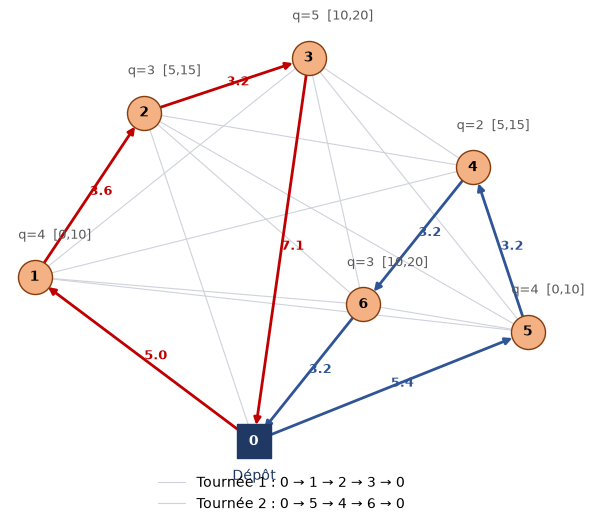

In [6]:
graphe([([0,1,2,3,0],'#c00000'),([0,5,4,6,0],'#2f5597')])

*Figure 2 – Solution optimale : deux tournées (rouge et bleu) et durées des arcs utilisés*

| Tournée | Parcours | Charge / Q | Durée |
|---|---|---|---|
| **Tournée 1** | 0 → 1 → 2 → 3 → 0 | 12 / 12 | 18.9 min |
| **Tournée 2** | 0 → 5 → 4 → 6 → 0 | 9 / 12 | 15.0 min |
| **Total** | | | 33.9 min |

**Lecture :** la tournée 1 est pleine (4 + 3 + 5 = 12) et la tournée 2 n'est chargée qu'à 9 sur 12. Chaque client est bien visité une seule fois, aucune capacité n'est dépassée et chaque livraison commence dans sa fenêtre (vérification dans la cellule suivante) : ce sont exactement les contraintes du modèle. Comme l'instance est petite, cette solution a été confirmée optimale en énumérant toutes les répartitions possibles des clients entre les deux camions et tous les ordres de visite. C'est l'équivalent de ce que fait le solveur PLNE de la section 4.1. Sur une grande instance, cette énumération devient impossible, d'où le recours aux métaheuristiques.

*Remarque :* les coordonnées des sommets et les fenêtres de temps sont choisies pour l'illustration. Elles ne proviennent pas des données réelles de l'ADEME.

In [7]:
# Vérification des tournées : capacité, horaires (avec attente) et fenêtres
c = [[0.0, 5.0, 6.3, 7.1, 6.4, 5.4, 3.2], [5.0, 0.0, 3.6, 6.4, 8.2, 9.1, 6.0],
     [6.3, 3.6, 0.0, 3.2, 6.1, 8.1, 5.3], [7.1, 6.4, 3.2, 0.0, 3.6, 6.4, 4.6],
     [6.4, 8.2, 6.1, 3.6, 0.0, 3.2, 3.2], [5.4, 9.1, 8.1, 6.4, 3.2, 0.0, 3.0],
     [3.2, 6.0, 5.3, 4.6, 3.2, 3.0, 0.0]]
s, Q = 1, 12


def verifier_tournee(tournee):
    charge, t, prec, duree, ok = sum(q[i] for i in tournee), 0.0, 0, 0.0, True
    for i in tournee:
        arrivee = t + (s if prec else 0) + c[prec][i]
        duree += c[prec][i]
        t = max(arrivee, tw[i][0])              # attente si arrivée avant l'ouverture
        ok &= t <= tw[i][1]
        print(f"   client {i} : arrivée {arrivee:4.1f}, début {t:4.1f}, fenêtre {list(tw[i])} "
              f"{'OK' if t <= tw[i][1] else 'VIOLÉE'}")
        prec = i
    duree += c[prec][0]
    print(f"   charge {charge}/{Q}, durée {duree:.1f} min, réalisable : {ok and charge <= Q}\n")
    return duree


total = 0
for nom, tour in [("Tournée 1", [1, 2, 3]), ("Tournée 2", [5, 4, 6])]:
    print(nom, ": 0 →", " → ".join(map(str, tour)), "→ 0")
    total += verifier_tournee(tour)
print(f"Durée totale : {total:.1f} min")

Tournée 1 : 0 → 1 → 2 → 3 → 0
   client 1 : arrivée  5.0, début  5.0, fenêtre [0, 10] OK
   client 2 : arrivée  9.6, début  9.6, fenêtre [5, 15] OK
   client 3 : arrivée 13.8, début 13.8, fenêtre [10, 20] OK
   charge 12/12, durée 18.9 min, réalisable : True

Tournée 2 : 0 → 5 → 4 → 6 → 0
   client 5 : arrivée  5.4, début  5.4, fenêtre [0, 10] OK
   client 4 : arrivée  9.6, début  9.6, fenêtre [5, 15] OK
   client 6 : arrivée 13.8, début 13.8, fenêtre [10, 20] OK
   charge 9/12, durée 15.0 min, réalisable : True

Durée totale : 33.9 min


## 6. Conversion du PLNE en PuLP

In [ ]:
import math
import pulp

# 1. DONNÉES (les mêmes que dans le graphe)
pos = {0: (0, 0), 1: (-4, 3), 2: (-2, 6), 3: (1, 7), 4: (4, 5), 5: (5, 2), 6: (2, 2.5)}  # coordonnées
q = {1: 4, 2: 3, 3: 5, 4: 2, 5: 4, 6: 3}                                                  # demandes
tw = {1: (0, 10), 2: (5, 15), 3: (10, 20), 4: (5, 15), 5: (0, 10), 6: (10, 20)}         # fenêtres [a, b]

V = list(pos)                       # tous les sommets : 0 = dépôt, 1..n = clients
N = [i for i in V if i != 0]        # uniquement les clients
K = range(2)                        # les camions (ici 2 : camion 0 et camion 1)
Q = 12                              # capacité de chaque camion
s = 1                               # temps de service chez chaque client (minutes)
M = 100                             # « grand nombre » de la contrainte 6

# Matrice des durées c_ij = distance euclidienne entre i et j (Pythagore)
c = {(i, j): round(math.dist(pos[i], pos[j]), 1) for i in V for j in V if i != j}

# 2. LE PROBLÈME : on cherche le MINIMUM
prob = pulp.LpProblem("CVRPTW", pulp.LpMinimize)

# 3. VARIABLES DE DÉCISION
# x[i, j, k] = 1 si le camion k va directement de i à j, 0 sinon (binaire)
x = {(i, j, k): pulp.LpVariable(f"x_{i}_{j}_{k}", cat="Binary") for (i, j) in c for k in K}

# u[i] = charge cumulée du camion après le client i (sert à MTZ)
u = {i: pulp.LpVariable(f"u_{i}", lowBound=0) for i in N}

# T[i, k] = heure à laquelle le camion k commence la livraison chez i
T = {(i, k): pulp.LpVariable(f"T_{i}_{k}", lowBound=0) for i in V for k in K}

# 4. FONCTION OBJECTIF
prob += pulp.lpSum(c[i, j] * x[i, j, k] for (i, j) in c for k in K)

# 5. CONTRAINTES

# --- Contrainte 1 : visite unique de chaque client ---
for j in N:
    prob += pulp.lpSum(x[i, j, k] for i in V if i != j for k in K) == 1

# --- Contrainte 2 : flux et continuité des tournées ---
for k in K:
    for j in V:
        prob += (pulp.lpSum(x[i, j, k] for i in V if i != j)
                 == pulp.lpSum(x[j, l, k] for l in V if l != j))

# --- Contrainte 3 : capacité maximale du véhicule ---

for k in K:
    prob += pulp.lpSum(q[j] * x[i, j, k] for (i, j) in c if j != 0) <= Q

# --- Contrainte 4 : élimination des sous-tours (MTZ) ---

for i in N:
    for j in N:
        if i != j:
            for k in K:
                prob += u[i] - u[j] + Q * x[i, j, k] <= Q - q[j]

# Bornes de MTZ : q_i ≤ u_i ≤ Q   ∀ i ∈ N
# → la charge cumulée est au moins la demande du client et jamais plus que la capacité
for i in N:
    prob += u[i] >= q[i]
    prob += u[i] <= Q

# --- Contrainte 5 : départ du dépôt ---
for k in K:
    prob += pulp.lpSum(x[0, j, k] for j in N) <= 1

# Heure de départ : T_0k = 0   ∀ k
# → tous les camions partent du dépôt à t = 0
for k in K:
    prob += T[0, k] == 0

# --- Contrainte 6 : enchaînement des horaires ---
for (i, j) in c:
    if j != 0:
        for k in K:
            prob += T[i, k] + (s if i != 0 else 0) + c[i, j] - T[j, k] <= M * (1 - x[i, j, k])

# --- Contrainte 7 : fenêtres de temps ---
for i in N:
    for k in K:
        prob += T[i, k] >= tw[i][0]
        prob += T[i, k] <= tw[i][1]

# 6. RÉSOLUTION (solveur CBC, livré avec PuLP)
prob.solve(pulp.PULP_CBC_CMD(msg=False))
print("Statut :", pulp.LpStatus[prob.status])
print(f"Durée totale optimale : {pulp.value(prob.objective):.1f} min\n")

# 7. LECTURE DE LA SOLUTION
for k in K:
    tournee, i = [0], 0
    while True:
        i = next((j for j in V if j != i and x[i, j, k].value() > 0.5), None)
        if i is None or i == 0:
            break
        tournee.append(i)
    if len(tournee) > 1:
        print(f"Camion {k + 1} : {' → '.join(map(str, tournee))} → 0")

Statut : Optimal
Durée totale optimale : 33.9 min

Camion 1 : 0 → 1 → 2 → 3 → 0
Camion 2 : 0 → 5 → 4 → 6 → 0


## Résumé
| Notion | Définition simple |
|---|---|
| **Objectif** | Minimiser le temps total des camions pour réduire la pollution et les coûts. |
| **Graphe** | Une carte où les lieux sont des points (sommets) et les routes des traits (arcs) pondérés par un temps de trajet. |
| **NP-difficile** | Problème tellement vaste qu’il est impossible de tester toutes les solutions une par une sur de grandes cartes. |
| **PLNE (exact)** | Équations mathématiques strictes qui donnent la meilleure réponse absolue, mais lentes sur de grands réseaux. |
| **Métaheuristique** | Stratégie d’exploration « intelligente » des trajets qui donne une très bonne solution en quelques secondes. |

# Livrable 2

## 0. Description formelle de la méthode : GRASP + Recherche Tabou

### 0.1 Pourquoi une métaheuristique ?

Le CVRPTW est NP-difficile (livrable 1) : la PLNE résolue par PuLP donne l'optimum sur l'instance de 6 clients, mais le temps de résolution explose dès quelques dizaines de clients. Pour des instances de 100 à plusieurs milliers de clients, on cherche une **bonne solution en un temps limité**, sans garantie d'optimalité. On combine deux métaheuristiques vues en cours :

- **GRASP** (*Greedy Randomized Adaptive Search Procedure*, Feo et Resende, 1995) pour **construire** des solutions de départ variées ;
- **Recherche Tabou** (Glover, 1986) pour les **améliorer** sans rester bloqué dans le premier optimum local.

### 0.2 Données

| Notation | Signification |
|---|---|
| $V = \{0, 1, \dots, n\}$ | sommets, $0$ = dépôt, $C = \{1, \dots, n\}$ = clients |
| $d_{ij}$ | distance (= durée de trajet) entre $i$ et $j$, symétrique |
| $q_i$ | demande du client $i$ ($q_0 = 0$) |
| $Q$ | capacité d'un camion (flotte homogène) |
| $[a_i, b_i]$ | fenêtre de temps du client $i$ ($[a_0, b_0]$ : ouverture du dépôt) |
| $s_i$ | temps de service chez $i$ ($s_0 = 0$) |

Pour le CVRP simple : $a_i = 0$, $b_i = +\infty$, $s_i = 0$.

### 0.3 Définition d'une solution

Une solution est un ensemble de tournées $S = \{R_1, \dots, R_m\}$. Chaque tournée est une **suite ordonnée** de clients $R_k = (c_1, c_2, \dots, c_L)$, le dépôt étant implicite au début et à la fin : $0 \to c_1 \to \dots \to c_L \to 0$.

En Python : `[[1, 2, 3], [5, 4, 6]]` $\Leftrightarrow$ $0 \to 1 \to 2 \to 3 \to 0$ et $0 \to 5 \to 4 \to 6 \to 0$.

Le nombre de camions $m$ n'est pas fixé à l'avance : il découle de la construction.

**Fonction objectif** (distance totale) :
$$f(S) = \sum_{k=1}^{m} \left( d_{0 c_1} + \sum_{l=1}^{L-1} d_{c_l c_{l+1}} + d_{c_L 0} \right)$$

**Réalisabilité** d'une tournée $R = (c_1, \dots, c_L)$ :

1. Capacité : $\sum_{l=1}^{L} q_{c_l} \le Q$
2. Fenêtres de temps, avec attente autorisée. Heure de début de service $h_l$ chez $c_l$ (avec $c_0 = 0$, $h_0 = 0$) :
$$h_l = \max\left(h_{l-1} + s_{c_{l-1}} + d_{c_{l-1} c_l},\; a_{c_l}\right) \quad \text{et} \quad h_l \le b_{c_l}$$
3. Retour au dépôt avant sa fermeture : $h_L + s_{c_L} + d_{c_L 0} \le b_0$

Une solution est réalisable si chaque client apparaît dans **exactement une** tournée et si toutes les tournées sont réalisables. On ne visite **que** des solutions réalisables : un mouvement qui viole une contrainte est rejeté.

### 0.4 Construction GRASP

On construit les tournées une par une, en ajoutant un client à la fin de la tournée courante.

1. **Candidats** : clients non visités $j$ qu'on peut ajouter après le dernier client $i$ sans violer capacité, fenêtre de $j$, ni retour au dépôt. Le test est en $O(1)$ grâce à la charge et l'heure courantes du camion.
2. **Score** (fonction gloutonne) : $g(j) = d_{ij} + 0{,}1 \cdot b_j$. On favorise les clients proches **et** pressés (fenêtre qui ferme tôt). Sans fenêtres : $g(j) = d_{ij}$.
3. **Liste restreinte de candidats (RCL)** :
$$RCL = \{\, j \;:\; g(j) \le g_{min} + \alpha\,(g_{max} - g_{min}) \,\}$$
4. **Choix aléatoire** d'un client dans la RCL.
5. S'il n'y a plus de candidat, on ferme la tournée et on en ouvre une nouvelle.

Le paramètre $\alpha \in [0, 1]$ règle le compromis : $\alpha = 0$ donne le glouton pur (plus proche voisin), $\alpha = 1$ l'aléatoire pur. Valeur retenue après l'étude de sensibilité : $\alpha = 0{,}1$ jusqu'à 500 clients, $\alpha = 0$ au-delà.

### 0.5 Structure de voisinage

Un voisin de $S$ est obtenu par **un mouvement** élémentaire. Soit $c$ un client placé entre $a$ et $b$ dans sa tournée.

| Mouvement | Description | Variation de coût $\Delta$ |
|---|---|---|
| **Relocate** | retirer $c$ et l'insérer entre $x$ et $y$ (même tournée, autre tournée, ou nouveau camion) | $(d_{ab} - d_{ac} - d_{cb}) + (d_{xc} + d_{cy} - d_{xy})$ |
| **Swap** | échanger $c$ (entre $a$ et $b$) avec $d$ (entre $e$ et $f$) d'une autre tournée | $(d_{ad} + d_{db} - d_{ac} - d_{cb}) + (d_{ec} + d_{cf} - d_{ed} - d_{df})$ |
| **2-opt** (option) | inverser le morceau $c \dots e$ d'une tournée : $a \to [c \dots e] \to f$ devient $a \to [e \dots c] \to f$ | $d_{ae} + d_{cf} - d_{ac} - d_{ef}$ |

Le coût d'un voisin vaut $f(S') = f(S) + \Delta$. **Évaluer un voisin coûte $O(1)$** (3 ou 4 distances) au lieu de recalculer $f$ en $O(n)$. La réalisabilité n'est vérifiée que pour les mouvements qui améliorent le meilleur $\Delta$ trouvé, et seulement sur les 1 ou 2 tournées modifiées.

**Réductions du voisinage** (pour les grandes instances) :

- **Échantillonnage** : à chaque itération, on ne déplace que $E = 25$ clients tirés au hasard.
- **K plus proches voisins** (au-delà de 500 clients) : $c$ n'est inséré que juste avant ou juste après un de ses $K = 30$ plus proches voisins, et n'est échangé qu'avec eux.

Taille du voisinage exploré par itération : $O(E \cdot n)$ sans restriction, $O(E \cdot K)$ avec.

### 0.6 Recherche Tabou

À chaque itération, on passe au **meilleur voisin non tabou**, même s'il est moins bon que la solution courante : c'est ce qui permet de sortir d'un optimum local.

- **Attribut tabou** : les clients touchés par le mouvement (le client déplacé pour un relocate, les deux clients pour un swap ou un 2-opt). Pendant $T$ itérations, tout mouvement qui touche un de ces clients est interdit. On rend tabou un **attribut** et non la solution entière, comme dans le workshop, car comparer des solutions complètes serait coûteux et trop peu restrictif.
- **Durée tabou** : $T = 10$, gérée par une file de taille fixe (`deque(maxlen=T)`).
- **Critère d'aspiration** : un mouvement tabou est quand même accepté s'il donne une solution meilleure que la meilleure trouvée depuis le début.

### 0.7 Critères d'arrêt et multi-start

- **Tabou** : arrêt après $I = 30$ itérations consécutives sans amélioration du record, ou quand le temps total est écoulé.
- **Multi-start (GRASP)** : on répète construction + tabou tant que le temps limite n'est pas atteint (20 s par défaut), et on garde la meilleure solution.

### 0.8 Pseudo-code

```
fonction GRASP_TABOU(temps_max, α, T, I, E)
    S* ← aucune ; f* ← +∞
    tant que temps < temps_max :
        S ← CONSTRUCTION_GRASP(α)
        S ← RECHERCHE_TABOU(S, T, I, E)
        si f(S) < f* : S* ← S ; f* ← f(S)
    renvoyer S*

fonction RECHERCHE_TABOU(S, T, I, E)
    tabou ← file vide de taille T
    meilleure ← S ; sans_amelioration ← 0
    tant que sans_amelioration < I et temps non écoulé :
        meilleur_mvt ← aucun ; Δ* ← +∞
        pour chaque mouvement m du voisinage de S (E clients tirés au hasard) :
            si Δ(m) < Δ* :
                si (m non tabou ou f(S) + Δ(m) < f(meilleure)) et m réalisable :
                    meilleur_mvt ← m ; Δ* ← Δ(m)
        S ← appliquer(S, meilleur_mvt) ; ajouter les clients de meilleur_mvt à tabou
        si f(S) < f(meilleure) : meilleure ← S ; sans_amelioration ← 0
        sinon : sans_amelioration ← sans_amelioration + 1
    renvoyer meilleure
```

### 0.9 Complexité

| Étape | Complexité |
|---|---|
| Matrice des distances | $O(n^2)$ en temps et en mémoire |
| K plus proches voisins | $O(n^2 \log n)$ (tri de chaque ligne), une seule fois |
| Une construction GRASP | $O(n^2)$ : chaque ajout parcourt les clients non visités, test en $O(1)$ |
| Une itération tabou | $O(E \cdot n)$ mouvements, ou $O(E \cdot K)$ avec les K voisins, chacun évalué en $O(1)$, plus $O(L)$ par test de réalisabilité |

### 0.10 Paramètres

| Paramètre | Rôle | Valeur |
|---|---|---|
| $\alpha$ | taille de la RCL (aléatoire de la construction) | 0,1 ($n \le 500$), 0 au-delà |
| $T$ (`taille_tabou`) | durée tabou | 10 |
| $I$ (`iter_max`) | itérations sans amélioration avant arrêt | 30 |
| $E$ (`taille_echantillon`) | clients testés par itération | 25 |
| $K$ (`K_VOISINS`) | proches voisins (si $n > 500$) | 30 |
| `UTILISER_2OPT` | active le 2-opt | False |
| `temps_max` | temps total | 20 s (benchmark) |

Ces valeurs viennent de l'étude expérimentale (sections 5 à 7).

## 1. GRASP + Recherche Tabou : le code

On reprend la logique du workshop (sac à dos) et on l'adapte au CVRPTW :

| Workshop (sac à dos) | Projet (CVRPTW) |
|---|---|
| solution = tuple de booléens | solution = liste de tournées `[[1, 2, 3], [5, 4, 6]]` (dépôt implicite) |
| `poids_contenu(sac) <= capacite` | `tournee_valide(t)` : capacité + fenêtres de temps (attente autorisée) |
| `random_solution()` | `grasp_construction(alpha)` : glouton randomisé avec une RCL |
| voisin = inverser un objet | voisin = **relocate** (déplacer un client) ou **swap** (échanger deux clients) |
| liste tabou de solutions | liste tabou de **clients déplacés** + critère d'aspiration |
| multi-start | `grasp_tabou()` : on répète construction + tabou et on garde la meilleure |

La cellule ci-dessous écrit le fichier `algorithmes/grasp_tabou_cvrptw.py` (avec `%%writefile`) pour qu'on puisse l'importer ensuite avec `from algorithmes import grasp_tabou_cvrptw as g`.

In [ ]:
%%writefile algorithmes/grasp_tabou_cvrptw.py
"""
Livrable 2 - GRASP + Recherche Tabou pour le CVRPTW
====================================================

Idée générale (même logique que le Workshop du sac à dos) :
  - une SOLUTION = une liste de tournées, chaque tournée = une liste de clients
    (le dépôt 0 n'est pas écrit, il est implicite au début et à la fin)
        ex : [[1, 2, 3], [5, 4, 6]]  <=>  0→1→2→3→0  et  0→5→4→6→0
  - GRASP  = construction gloutonne RANDOMISÉE (remplace random_solution())
  - TABOU  = on va au meilleur voisin non tabou, même s'il est moins bon
  - MULTI-START = on répète GRASP + Tabou plusieurs fois et on garde le meilleur

Fonctionne pour :
  - le CVRP   (si pas de fenêtres : a = 0, b = très grand, service = 0)
  - le CVRPTW (fenêtres de temps [a_i, b_i], attente autorisée)
"""

import math
import random
import time
from collections import deque

import numpy as np
from scipy.spatial import cKDTree

# Active / désactive le mouvement 2-opt dans le voisinage.
# Sur nos tests (100 clients aléatoires) il n'améliorait pas le coût :
# on le laisse en OPTION pour le comparer sur les instances VRPLIB.
UTILISER_2OPT = False

# Voisinage restreint : pour chaque client, on ne regarde que ses K plus proches
# voisins (insertion à côté d'eux, échange avec eux) au lieu de TOUS les clients.
# Indispensable pour les grandes instances. None = voisinage complet.
# On ne l'active qu'au-delà de SEUIL_KNN clients : sur les petites instances
# avec fenêtres de temps, la bonne place d'un client n'est pas toujours à côté
# de ses voisins géographiques (testé : RC2 passait de 5,2 % à 8,4 % de gap).
K_VOISINS = 30
SEUIL_KNN = 500

# Active / désactive le mouvement 2-opt* (échange des fins de deux tournées).
UTILISER_2OPT_ETOILE = True

# Au-delà de SEUIL_MATRICE clients, on ne construit plus la matrice des distances :
# elle ne tient pas en mémoire. Les distances sont calculées à la demande.
SEUIL_MATRICE = 5000

# AJOUT interface : réglages remplis par l'interface (voir algorithmes/methodes.py).
# Avec ces valeurs par défaut, le code fonctionne exactement comme avant.
depart = 0.0      # heure de départ des camions (360 = 6h00 pour les instances de Lorraine)
k_max = None      # nombre de camions disponibles (None = illimité)


def trajet(i, j, heure):
    """AJOUT interface : durée du trajet i -> j en partant à 'heure'.
    Par défaut c'est la distance ; l'interface la remplace quand le trafic est activé."""
    return dist[i][j]


# =============================================================================
# 1. DONNÉES DE L'INSTANCE
# =============================================================================
# On stocke tout dans des variables globales, comme dans le workshop

class Ligne:
    """
    Remplace une ligne de la matrice des distances pour les très grandes instances :
    dist[i] est une Ligne, et dist[i][j] CALCULE la distance au moment où on la
    demande. On écrit toujours dist[i][j] : le reste du code ne change pas.
    """

    def __init__(self, i):
        self.x, self.y = X[i], Y[i]

    def __getitem__(self, j):            # appelé par Python quand on écrit dist[i][j]
        d = math.hypot(self.x - X[j], self.y - Y[j])
        if ARRONDI == "entier":
            return float(round(d))
        if ARRONDI == "dixieme":
            return math.floor(d * 10) / 10
        return d


def charger_instance(coords, demandes, Q_cap, fenetres=None, service=None,
                     arrondi=None):
    """
    Prépare l'instance.
    coords   : liste de (x, y), indice 0 = dépôt
    demandes : liste des demandes q_i (q_0 = 0)
    Q_cap    : capacité d'un camion
    fenetres : liste de (a_i, b_i)  (None => pas de fenêtres = CVRP)
    service  : liste des temps de service s_i (None => 0 partout)
    arrondi  : None (distance exacte), "dixieme" (tronquée à 0,1) ou "entier"
               -> conventions des instances de référence (voir benchmark)
    """
    global n, q, Q, tw, s, dist, proches, geante, X, Y, ARRONDI, arbre

    n = len(coords)                      # nombre de sommets (dépôt compris)
    q = list(demandes)
    Q = Q_cap
    tw = list(fenetres) if fenetres is not None else [(0, float("inf"))] * n
    s = list(service) if service is not None else [0] * n

    # TRÈS grande instance : la matrice n x n ne tient pas en mémoire
    # (30 000 clients = 900 millions de distances, environ 29 Go en listes Python).
    geante = n - 1 > SEUIL_MATRICE
    if geante:
        c = np.array(coords, dtype=float)
        X, Y, ARRONDI = c[:, 0].tolist(), c[:, 1].tolist(), arrondi
        dist = [Ligne(i) for i in range(n)]          # dist[i][j] calculé à la demande
        # K plus proches voisins avec un arbre de recherche spatiale (pas de matrice)
        k = min(K_VOISINS or 30, n - 2)
        arbre = cKDTree(c[1:])                       # les clients, sans le dépôt
        _, idx = arbre.query(c, k=k + 1)             # +1 : chaque client se trouve lui-même
        idx += 1                                     # indice dans l'arbre -> numéro de client
        proches = [[j for j in ligne if j != i][:k] for i, ligne in enumerate(idx.tolist())]
        return

    # PRÉ-CALCUL de la matrice des distances avec numpy (calcul vectorisé :
    # toutes les distances d'un coup, bien plus rapide qu'une double boucle)
    c = np.array(coords, dtype=float)
    d = np.sqrt(((c[:, None, :] - c[None, :, :]) ** 2).sum(axis=2))
    if arrondi == "dixieme":
        d = np.floor(d * 10) / 10
    elif arrondi == "entier":
        d = np.rint(d)
    # on repasse en listes Python : lire dist[i][j] case par case est plus
    # rapide sur une liste que sur un tableau numpy
    dist = d.tolist()

    # Les K plus proches voisins de chaque client (le dépôt 0 est exclu)
    petite = n - 1 <= SEUIL_KNN
    k = n - 2 if (K_VOISINS is None or petite) else min(K_VOISINS, n - 2)
    d_clients = d.copy()
    d_clients[:, 0] = np.inf                 # on ne veut pas le dépôt
    np.fill_diagonal(d_clients, np.inf)      # ni le client lui-même
    if k > 0:
        proches = np.argsort(d_clients, axis=1)[:, :k].tolist()
    else:
        proches = [[] for _ in range(n)]


# =============================================================================
# 2. FONCTIONS DE BASE (équivalent de poids_contenu / valeur_contenu)
# =============================================================================

def cout_tournee(tournee):
    """Distance totale d'une tournée (dépôt → clients → dépôt)."""
    if not tournee:
        return 0.0
    c = dist[0][tournee[0]] + dist[tournee[-1]][0]
    for i in range(len(tournee) - 1):
        c += dist[tournee[i]][tournee[i + 1]]
    return c


def cout_solution(solution):
    """Coût total = somme des coûts des tournées (fonction objectif Z)."""
    return sum(cout_tournee(t) for t in solution)


def tournee_valide(tournee):
    """
    Vérifie capacité ET fenêtres de temps (avec attente autorisée).
    C'est l'équivalent de 'poids_contenu(sac) <= capacite' du workshop.
    """
    # 1) Capacité
    if sum(q[i] for i in tournee) > Q:
        return False

    # 2) Fenêtres de temps : on simule le trajet du camion
    t = depart       # heure de départ du dépôt (AJOUT interface : 0 avant)
    prec = 0         # on part du dépôt
    for i in tournee:
        t = t + s[prec]                   # fin du service chez le précédent
        t = t + trajet(prec, i, t)        # arrivée chez i (AJOUT interface : trajet() gère le trafic)
        t = max(t, tw[i][0])              # attente si on arrive trop tôt
        if t > tw[i][1]:                  # trop tard => interdit
            return False
        prec = i

    # 3) Retour au dépôt avant sa fermeture
    t = t + s[prec]
    t = t + trajet(prec, 0, t)
    return t <= tw[0][1]


# =============================================================================
# 3. CONSTRUCTION GRASP (remplace random_solution() du workshop)
# =============================================================================

def grasp_construction(alpha=0.3):
    """
    Construit une solution tournée par tournée.
    À chaque étape :
      1. on liste les clients qu'on peut ajouter à la fin de la tournée courante
         sans violer capacité / fenêtres
      2. on les classe par 'distance' depuis le dernier client
      3. RCL (Restricted Candidate List) : on garde les meilleurs
         (ceux dont le score <= min + alpha * (max - min))
      4. on en tire un AU HASARD dans la RCL  => c'est le côté "randomisé"
    alpha = 0 : glouton pur (plus proche voisin)  /  alpha = 1 : aléatoire pur
    """
    non_visites = set(range(1, n))
    solution = []

    while non_visites:
        tournee = []
        charge, heure = 0, depart   # charge du camion et heure d'arrivée chez le dernier
        while True:
            dernier = tournee[-1] if tournee else 0

            # 1. candidats réalisables, testés en O(1) chacun : on ne re-simule
            #    PAS toute la tournée, on part de (charge, heure) du dernier client
            candidats = []
            for j in non_visites:
                if charge + q[j] > Q:
                    continue                                   # capacité
                fin = heure + s[dernier]                       # départ de chez le dernier
                arrivee = max(fin + trajet(dernier, j, fin), tw[j][0])
                if arrivee > tw[j][1]:
                    continue                                   # trop tard chez j
                if arrivee + s[j] + trajet(j, 0, arrivee + s[j]) > tw[0][1]:
                    continue                                   # retour au dépôt
                candidats.append(j)
            if not candidats:
                break  # plus rien ne rentre => on ferme la tournée

            # 2. score = distance + un peu d'urgence (fermeture de fenêtre)
            #    => on privilégie les clients proches ET pressés
            score = {j: dist[dernier][j] + 0.1 * tw[j][1] if tw[j][1] != float("inf")
                     else dist[dernier][j] for j in candidats}

            # 3. RCL
            smin, smax = min(score.values()), max(score.values())
            seuil = smin + alpha * (smax - smin)
            rcl = [j for j in candidats if score[j] <= seuil]

            # 4. choix aléatoire dans la RCL
            choisi = random.choice(rcl)
            fin = heure + s[dernier]
            heure = max(fin + trajet(dernier, choisi, fin), tw[choisi][0])
            charge += q[choisi]
            tournee.append(choisi)
            non_visites.remove(choisi)

        if not tournee:
            # un client ne rentre même pas seul dans un camion : instance infaisable
            raise ValueError(f"Clients impossibles à servir : {non_visites}")
        solution.append(tournee)

    return solution


def construction_voisins():
    """
    Construction pour les TRÈS grandes instances (plus de SEUIL_MATRICE clients).
    Même idée que le plus proche voisin, mais on ne cherche le client suivant que
    parmi les K plus proches voisins du dernier client, au lieu de tous les clients
    restants : sinon 30 000 clients = environ 450 millions de tests.
    """
    libre = [True] * n                               # libre[j] : j n'est pas encore livré
    libre[0] = False
    reste = n - 1
    # pour démarrer une tournée : le client libre le plus proche du dépôt
    ordre_depot = sorted(range(1, n), key=lambda j: dist[0][j])
    curseur = 0
    solution = []

    while reste:
        while not libre[ordre_depot[curseur]]:
            curseur += 1
        tournee, charge, heure, dernier = [], 0, depart, 0
        candidats = [ordre_depot[curseur]]
        while True:
            # on garde les candidats qui respectent capacité et fenêtres de temps
            fin = heure + s[dernier]
            possibles = []
            for j in candidats:
                if charge + q[j] > Q:
                    continue
                arrivee = max(fin + trajet(dernier, j, fin), tw[j][0])
                if arrivee > tw[j][1]:
                    continue
                if arrivee + s[j] + trajet(j, 0, arrivee + s[j]) > tw[0][1]:
                    continue
                possibles.append((dist[dernier][j], arrivee, j))
            if not possibles:
                break                                # plus rien ne rentre : on ferme la tournée
            _, heure, dernier = min(possibles)       # le plus proche
            charge += q[dernier]
            tournee.append(dernier)
            libre[dernier] = False
            reste -= 1

            # candidats suivants : les voisins encore libres du nouveau dernier client
            candidats = [j for j in proches[dernier] if libre[j]]
            k = len(proches[dernier])
            while not candidats and reste and k < n - 1:
                k = min(4 * k, n - 1)                # tous pris : on regarde plus loin
                _, plus_loin = arbre.query([X[dernier], Y[dernier]], k=k)
                candidats = [j + 1 for j in plus_loin.tolist() if libre[j + 1]]

        if not tournee:
            raise ValueError(f"Client impossible à servir : {candidats}")
        solution.append(tournee)

    return solution


# =============================================================================
# 4. VOISINAGE (équivalent de voisinage(sac) du workshop)
# =============================================================================
# Workshop : un voisin = on inverse UN objet du sac.
# Ici      : un voisin = on DÉPLACE UN client (relocate)
#            ou on ÉCHANGE deux clients (swap)
#            ou on INVERSE un morceau de tournée (2-opt).
#
# ACCÉLÉRATION (version 2) :
#   Avant, pour chaque voisin on recopiait TOUTE la solution puis on
#   recalculait TOUT le coût  => O(n) par voisin, beaucoup trop lent.
#   Maintenant, un voisin n'est plus une solution complète mais un MOUVEMENT
#   (quelques indices). Son coût se calcule par DIFFÉRENCE (delta) avec
#   seulement 3 ou 4 distances => O(1) par voisin.
#   On ne vérifie la validité (capacité / fenêtres) QUE si le mouvement est
#   intéressant, et on ne construit la nouvelle solution QUE pour le
#   mouvement finalement choisi.

def autour(tournee, p):
    """Renvoie (précédent, suivant) du client en position p (0 = dépôt)."""
    prec = tournee[p - 1] if p > 0 else 0
    suiv = tournee[p + 1] if p < len(tournee) - 1 else 0
    return prec, suiv


def voisinage(solution, taille_echantillon=None):
    """
    Générateur de mouvements : (delta, mouvement).
      delta     = nouveau coût - coût actuel (négatif = amélioration)
      mouvement = ("relocate" | "swap" | "2opt", r1, p1, r2, p2)
    ATTENTION : la validité n'est PAS vérifiée ici (voir mouvement_valide).
    taille_echantillon : pour les grandes instances, on ne teste qu'un
    échantillon aléatoire de clients (sinon le voisinage est énorme).
    """
    # position de chaque client : position[client] = (tournée, rang)
    position = {}
    for r, t in enumerate(solution):
        for p, cl in enumerate(t):
            position[cl] = (r, p)

    tous_clients = list(position.values())
    if taille_echantillon and len(tous_clients) > taille_echantillon:
        tous_clients = random.sample(tous_clients, taille_echantillon)

    for (r1, p1) in tous_clients:
        t1 = solution[r1]
        c = t1[p1]
        a, b = autour(t1, p1)
        # gain obtenu en retirant c :  a -> c -> b  devient  a -> b
        delta_retrait = dist[a][b] - dist[a][c] - dist[c][b]

        # ----- RELOCATE : on retire c et on le remet entre x et y -----
        # ouvrir un nouveau camion : 0 -> c -> 0 (AJOUT interface : seulement s'il en reste un)
        if len(t1) > 1 and (k_max is None or len(solution) < k_max):
            yield delta_retrait + 2 * dist[0][c], ("relocate", r1, p1, len(solution), 0)

        # On n'essaie que les positions JUSTE AVANT ou JUSTE APRÈS un des K plus
        # proches voisins v de c : insérer c loin de tout n'est jamais intéressant.
        for v in proches[c]:
            r2, pv = position[v]
            t2 = solution[r2]
            for p2 in (pv, pv + 1):                  # insertion AVANT la position p2
                if r1 == r2 and (p2 == p1 or p2 == p1 + 1):
                    continue                         # même position
                x = t2[p2 - 1] if p2 > 0 else 0
                y = t2[p2] if p2 < len(t2) else 0
                if r1 == r2:                         # même tournée : c n'est plus là
                    if x == c:
                        x = a
                    if y == c:
                        y = b
                # coût ajouté en insérant c :  x -> y  devient  x -> c -> y
                delta_insert = dist[x][c] + dist[c][y] - dist[x][y]
                yield delta_retrait + delta_insert, ("relocate", r1, p1, r2, p2)

        # ----- SWAP : on échange c avec un proche voisin d d'une autre tournée -----
        for d in proches[c]:
            r2, p2 = position[d]
            if r2 == r1:
                continue
            t2 = solution[r2]
            e, f = autour(t2, p2)
            delta = (dist[a][d] + dist[d][b] - dist[a][c] - dist[c][b]
                     + dist[e][c] + dist[c][f] - dist[e][d] - dist[d][f])
            yield delta, ("swap", r1, p1, r2, p2)

        # ----- 2-OPT* : on échange les FINS de deux tournées -----
        #   t1 = [... c | b ...]   et   t2 = [... x | v ...]
        #   deviennent  [... c , v ...]   et   [... x , b ...]
        #   Aucun morceau n'est retourné : le sens du temps est gardé (fenêtres).
        #   Si c est le dernier de t1 et v le premier de t2, les deux tournées
        #   FUSIONNENT : c'est ce mouvement qui fait baisser le nombre de camions.
        if UTILISER_2OPT_ETOILE:
            for v in proches[c]:
                r2, pv = position[v]
                if r2 == r1:
                    continue
                t2 = solution[r2]
                x = t2[pv - 1] if pv > 0 else 0      # client juste avant v (0 = dépôt)
                # 2 arcs retirés : (c,b) et (x,v)  /  2 arcs ajoutés : (c,v) et (x,b)
                delta = dist[c][v] + dist[x][b] - dist[c][b] - dist[x][v]
                yield delta, ("2opt*", r1, p1, r2, pv)

        # ----- 2-OPT : on inverse le morceau t1[p1..p2] DANS la même tournée -----
        #   a -> [c ... e] -> f   devient   a -> [e ... c] -> f
        #   seuls 2 arcs changent : (a,c) et (e,f) sont remplacés par (a,e) et (c,f)
        #   (le morceau du milieu garde la même longueur car dist est symétrique)
        if not UTILISER_2OPT:
            continue
        for p2 in range(p1 + 1, len(t1)):
            e = t1[p2]
            f = t1[p2 + 1] if p2 < len(t1) - 1 else 0
            delta = dist[a][e] + dist[c][f] - dist[a][c] - dist[e][f]
            yield delta, ("2opt", r1, p1, r1, p2)


def tournees_modifiees(solution, mouvement):
    """
    Construit UNIQUEMENT les tournées touchées par le mouvement.
    Renvoie un dict {indice_tournee: nouvelle_tournee}.
    """
    type_mvt, r1, p1, r2, p2 = mouvement
    if type_mvt == "swap":
        t1, t2 = solution[r1][:], solution[r2][:]
        t1[p1], t2[p2] = t2[p2], t1[p1]
        return {r1: t1, r2: t2}

    if type_mvt == "2opt":
        t = solution[r1]
        # on garde le début, on inverse le morceau [p1..p2], on garde la fin
        return {r1: t[:p1] + t[p1:p2 + 1][::-1] + t[p2 + 1:]}

    if type_mvt == "2opt*":
        t1, t2 = solution[r1], solution[r2]
        # début de t1 + fin de t2   /   début de t2 + fin de t1
        return {r1: t1[:p1 + 1] + t2[p2:], r2: t2[:p2] + t1[p1 + 1:]}

    # relocate
    c = solution[r1][p1]
    t1 = solution[r1][:p1] + solution[r1][p1 + 1:]
    if r1 == r2:
        p2 = p2 - 1 if p2 > p1 else p2   # les positions ont glissé d'un cran
        t1.insert(p2, c)
        return {r1: t1}
    t2 = solution[r2][:] if r2 < len(solution) else []
    t2.insert(p2, c)
    return {r1: t1, r2: t2}


def clients_touches(solution, mouvement):
    """
    Clients concernés par le mouvement (ce sont eux qu'on rend tabou).
      relocate : le client déplacé
      swap     : les 2 clients échangés
      2-opt    : les 2 extrémités du morceau inversé
      2-opt*   : les 2 clients qu'on relie (c et v)
    Sans ça, le 2-opt pourrait ré-inverser le morceau juste après => boucle.
    """
    type_mvt, r1, p1, r2, p2 = mouvement
    if type_mvt == "relocate":
        return (solution[r1][p1],)
    return (solution[r1][p1], solution[r2][p2])


def mouvement_valide(solution, mouvement):
    """Vérifie capacité + fenêtres sur les seules tournées modifiées."""
    return all(tournee_valide(t) for t in tournees_modifiees(solution, mouvement).values())


def appliquer_mouvement(solution, mouvement):
    """Renvoie la nouvelle solution (on ne recopie que les tournées touchées)."""
    nouvelle = solution[:] + [[]]        # [[]] : place pour un éventuel nouveau camion
    for r, t in tournees_modifiees(solution, mouvement).items():
        nouvelle[r] = t
    return [t for t in nouvelle if t]    # on retire les tournées vides


def supprimer_tournees(solution):
    """
    Essaie de vider les petites tournées en replaçant leurs clients ailleurs.
    Le tabou seul n'y arrive pas : il faudrait déplacer tous les clients d'une
    tournée un par un, et plusieurs de ces déplacements augmentent la distance.
    Ici on vide la tournée d'un coup ; si un client ne rentre nulle part, on annule.
    """
    sol = [t[:] for t in solution]
    charge = [sum(q[i] for i in t) for t in sol]

    for r in sorted(range(len(sol)), key=lambda r: len(sol[r])):   # les plus petites d'abord
        places = []                                  # (tournée, client) déjà replacés
        for c in sol[r]:
            meilleur, cout_min = None, float("inf")
            for r2, t in enumerate(sol):
                if r2 == r or not t or charge[r2] + q[c] > Q:
                    continue                         # même tournée, vide, ou trop chargée
                for p in range(len(t) + 1):          # toutes les positions d'insertion
                    x = t[p - 1] if p > 0 else 0
                    y = t[p] if p < len(t) else 0
                    d = dist[x][c] + dist[c][y] - dist[x][y]
                    if d < cout_min and tournee_valide(t[:p] + [c] + t[p:]):
                        meilleur, cout_min = (r2, p), d
            if meilleur is None:
                break                                # ce client ne rentre nulle part
            sol[meilleur[0]].insert(meilleur[1], c)
            charge[meilleur[0]] += q[c]
            places.append((meilleur[0], c))

        if len(places) == len(sol[r]):
            sol[r] = []                              # réussi : un camion de moins
        else:
            for r2, c in places:                     # échec : on remet tout comme avant
                sol[r2].remove(c)
                charge[r2] -= q[c]

    return [t for t in sol if t]


# =============================================================================
# 5. RECHERCHE TABOU (copie quasi conforme du workshop)
# =============================================================================

def recherche_tabou(solution_initiale, taille_tabou=10, iter_max=50,
                    taille_echantillon=None, heure_fin=None, suivi=None):
    """
    1. On part de la solution GRASP
    2. On prend le meilleur voisin dont le mouvement n'est pas tabou
       (même s'il est moins bon : c'est ce qui permet de sortir des optimums locaux)
    3. On rend tabou le client déplacé
    4. On s'arrête après iter_max itérations SANS amélioration
    Différence avec le workshop : on rend tabou un MOUVEMENT (le client déplacé)
    au lieu de la solution entière -> plus efficace pour le VRP.
    AJOUT interface : suivi(iteration, cout) est appelé à chaque nouveau record
                      (pour tracer une convergence ; l'interface ne s'en sert pas).
    """
    liste_tabou = deque(maxlen=taille_tabou)

    solution_courante = solution_initiale
    cout_courant = cout_solution(solution_initiale)   # calculé UNE seule fois
    meilleure_globale = solution_initiale
    cout_meilleure_globale = cout_courant

    nb_iter = 0
    iteration = 0                    # AJOUT interface (pour suivi)
    while nb_iter < iter_max:
        iteration += 1
        # arrêt forcé si le temps total est dépassé (grandes instances)
        if heure_fin and time.time() > heure_fin:
            break
        meilleur_mvt, delta_meilleur = None, float("inf")

        for delta, mvt in voisinage(solution_courante, taille_echantillon):
            # 1) test rapide sur le coût AVANT le test de validité (plus cher)
            if delta >= delta_meilleur:
                continue
            # 2) Critère d'ASPIRATION : un mouvement tabou est accepté s'il bat le record
            est_tabou = any(cl in liste_tabou
                            for cl in clients_touches(solution_courante, mvt))
            autorise = (not est_tabou
                        or cout_courant + delta < cout_meilleure_globale - 1e-9)
            # 3) seulement maintenant on vérifie capacité / fenêtres
            if autorise and mouvement_valide(solution_courante, mvt):
                meilleur_mvt, delta_meilleur = mvt, delta

        if meilleur_mvt is None:         # aucun voisin possible
            break

        # on passe au meilleur voisin non tabou (et on rend tabou les clients touchés)
        liste_tabou.extend(clients_touches(solution_courante, meilleur_mvt))
        solution_courante = appliquer_mouvement(solution_courante, meilleur_mvt)
        cout_courant += delta_meilleur   # mise à jour du coût par différence

        # mise à jour du record
        if cout_courant < cout_meilleure_globale - 1e-9:
            meilleure_globale = solution_courante
            cout_meilleure_globale = cout_courant
            nb_iter = 0
            if suivi:                    # AJOUT interface : courbe de convergence
                suivi(iteration, cout_meilleure_globale)
        else:
            nb_iter += 1

    return meilleure_globale


# =============================================================================
# 6. GRASP COMPLET = MULTI-START (construction + tabou), comme au workshop
# =============================================================================

def grasp_tabou(nb_starts=10, alpha=0.3, taille_tabou=10, iter_max=50,
                taille_echantillon=None, temps_max=None, verbose=True, suivi=None):
    """Répète (construction GRASP -> recherche tabou) et garde la meilleure."""
    meilleure, cout_meilleure = None, float("inf")
    debut = time.time()

    # Grande instance (plus de SEUIL_KNN clients) avec un temps limite : UN SEUL
    # départ, long. Recommencer de zéro ferait perdre le travail déjà fait, et la
    # construction redonne presque la même solution à chaque fois.
    un_seul_depart = bool(temps_max) and n - 1 > SEUIL_KNN

    for k in range(nb_starts):
        fin = debut + temps_max if temps_max else None
        if geante:
            # très grande instance : construction rapide, puis tabou jusqu'à la fin du temps
            sol = construction_voisins()
            if fin:
                sol = recherche_tabou(sol, taille_tabou, 10 ** 9, taille_echantillon, fin)
        elif un_seul_depart:
            # on vide des tournées, on améliore, on recommence une fois à mi-temps
            sol = supprimer_tournees(grasp_construction(alpha))
            sol = recherche_tabou(sol, taille_tabou, 10 ** 9, taille_echantillon,
                                  debut + temps_max / 2)
            sol = supprimer_tournees(sol)
            sol = recherche_tabou(sol, taille_tabou, 10 ** 9, taille_echantillon, fin)
        else:
            sol = grasp_construction(alpha)
            sol = recherche_tabou(sol, taille_tabou, iter_max, taille_echantillon, fin)
        c = cout_solution(sol)
        if verbose:
            print(f"start {k + 1:3d} : coût = {c:9.1f}  ({len(sol)} camions)")
        if c < cout_meilleure:
            meilleure, cout_meilleure = sol, c
            if suivi:                    # AJOUT interface : courbe de convergence
                suivi(k + 1, c)
        if geante or un_seul_depart or (temps_max and time.time() - debut > temps_max):
            break

    return meilleure, cout_meilleure


def verifier_solution(solution):
    """Contrôle final : chaque client visité 1 fois + toutes tournées valides."""
    clients = sorted(c for t in solution for c in t)
    return clients == list(range(1, n)) and all(tournee_valide(t) for t in solution)


# =============================================================================
# 7. TESTS
# =============================================================================
if __name__ == "__main__":
    random.seed(42)

    # ---- Test 1 : l'instance du livrable 1 (optimum PuLP = 33.9) ----
    print("=== Instance d'exemple (6 clients) ===")
    coords = [(0, 0), (-4, 3), (-2, 6), (1, 7), (4, 5), (5, 2), (2, 2.5)]
    demandes = [0, 4, 3, 5, 2, 4, 3]
    fenetres = [(0, 1000), (0, 10), (5, 15), (10, 20), (5, 15), (0, 10), (10, 20)]
    service = [0, 1, 1, 1, 1, 1, 1]
    charger_instance(coords, demandes, 12, fenetres, service)

    sol, c = grasp_tabou(nb_starts=5, verbose=False)
    print("Solution :", [[0] + t + [0] for t in sol])
    print(f"Coût = {c:.1f}  (optimum PuLP : 33.9)  valide : {verifier_solution(sol)}\n")

    # ---- Test 2 : instance aléatoire de 100 clients (CVRP) ----
    print("=== Instance aléatoire 100 clients ===")
    coords = [(50, 50)] + [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(100)]
    demandes = [0] + [random.randint(1, 10) for _ in range(100)]
    charger_instance(coords, demandes, 50)
    t0 = time.time()
    sol, c = grasp_tabou(nb_starts=3, iter_max=30, taille_echantillon=30)
    print(f"Meilleur coût = {c:.1f}, valide : {verifier_solution(sol)}, "
          f"temps = {time.time() - t0:.1f} s")

## 2. Accélération : le coût par différence (delta)

**Problème.** La première version, copiée du workshop, mettait **21 s pour 100 clients**. Pour chaque voisin, elle recopiait toute la solution, recalculait tout son coût, puis vérifiait sa validité : O(n) par voisin. Impossible pour des milliers de clients.

**Avant** (version 1) :
```python
voisin = [t[:] for t in solution]          # copie de TOUTE la solution
voisin[r1].pop(p1)
voisin[r2].insert(p2, client)
if tournee_valide(voisin[r1]) and tournee_valide(voisin[r2]):
    yield voisin, client
...
c = cout_solution(voisin)                  # recalcul de TOUT le coût
```

**Maintenant** (version 2) : un voisin n'est plus une solution complète mais un **mouvement**, quelques indices `("relocate", r1, p1, r2, p2)`. On procède en 3 temps.

**1. Coût par différence.** On calcule seulement ce qui change. Retirer `c` placé entre `a` et `b`, puis l'insérer entre `x` et `y` :
```python
delta_retrait = dist[a][b] - dist[a][c] - dist[c][b]   # a -> c -> b  devient  a -> b
delta_insert  = dist[x][c] + dist[c][y] - dist[x][y]   # x -> y  devient  x -> c -> y
yield delta_retrait + delta_insert, ("relocate", r1, p1, r2, p2)
```

**2. Validité vérifiée seulement si le mouvement est intéressant** (et seulement sur les 1 ou 2 tournées touchées) :
```python
if delta >= delta_meilleur:
    continue                               # test rapide : on jette
...
if autorise and mouvement_valide(solution_courante, mvt):
    meilleur_mvt, delta_meilleur = mvt, delta
```

**3. La nouvelle solution n'est construite qu'une fois**, pour le mouvement retenu :
```python
solution_courante = appliquer_mouvement(solution_courante, meilleur_mvt)
cout_courant += delta_meilleur             # plus besoin de cout_solution()
```

| Nouvelle fonction | Rôle |
|---|---|
| `autour` | client avant et client après une position |
| `voisinage` | produit les mouvements avec leur `delta` |
| `tournees_modifiees` | reconstruit seulement les tournées touchées |
| `mouvement_valide` | vérifie capacité + fenêtres sur ces tournées |
| `appliquer_mouvement` | construit la nouvelle solution |

La logique tabou ne change pas (même liste tabou, même aspiration).

**À retenir :** évaluer un voisin passe de O(n) à O(1). Résultat : **21 s → 1,3 s** sur 100 clients, pour une qualité équivalente.

In [ ]:
# Test : instance d'exemple du livrable 1, puis 100 clients aléatoires
import importlib, random, time
from algorithmes import grasp_tabou_cvrptw as g
importlib.reload(g)          # recharge le fichier si on l'a modifié

random.seed(42)
coords = [(0, 0), (-4, 3), (-2, 6), (1, 7), (4, 5), (5, 2), (2, 2.5)]
demandes = [0, 4, 3, 5, 2, 4, 3]
fenetres = [(0, 1000), (0, 10), (5, 15), (10, 20), (5, 15), (0, 10), (10, 20)]
service = [0, 1, 1, 1, 1, 1, 1]
g.charger_instance(coords, demandes, 12, fenetres, service)
sol, c = g.grasp_tabou(nb_starts=5, verbose=False)
print("Solution :", [[0] + t + [0] for t in sol])
print(f"Coût = {c:.1f}  (optimum PuLP : 33.9)  valide : {g.verifier_solution(sol)}")
print()

coords = [(50, 50)] + [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(100)]
demandes = [0] + [random.randint(1, 10) for _ in range(100)]
g.charger_instance(coords, demandes, 50)
t0 = time.time()
sol, c = g.grasp_tabou(nb_starts=3, iter_max=30, taille_echantillon=30)
print(f"Meilleur coût = {c:.1f}, valide : {g.verifier_solution(sol)}, temps = {time.time() - t0:.1f} s")

Solution : [[0, 1, 2, 3, 0], [0, 5, 4, 6, 0]]
Coût = 33.8  (optimum PuLP : 33.9)  valide : True

start   1 : coût =    1714.1  (11 camions)
start   2 : coût =    1501.0  (11 camions)
start   3 : coût =    1575.3  (11 camions)
Meilleur coût = 1501.0, valide : True, temps = 1.7 s


Vérification que le calcul par différence est juste : pour chaque voisin, on compare `coût actuel + delta` au coût recalculé entièrement. L'écart doit être quasi nul (erreurs d'arrondi des flottants).

In [ ]:
random.seed(1)
coords = [(50, 50)] + [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(40)]
g.charger_instance(coords, [0] + [random.randint(1, 10) for _ in range(40)], 50)

s = g.grasp_construction()
c = g.cout_solution(s)
erreur = max(abs(g.cout_solution(g.appliquer_mouvement(s, m)) - (c + d))
             for d, m in g.voisinage(s))
print("erreur max entre delta et recalcul complet =", erreur)

erreur max entre delta et recalcul complet = 2.2737367544323206e-13


## 3. Ajout d'un mouvement 2-opt (en option)

**Idée.** Le 2-opt inverse un morceau d'une tournée. C'est le mouvement classique pour « décroiser » un trajet :
`a -> [c ... e] -> f` devient `a -> [e ... c] -> f`. Seuls 2 trajets changent, donc le delta se calcule toujours avec 4 distances.

**Ajout 1, dans `voisinage`** :
```python
if not UTILISER_2OPT:
    continue
for p2 in range(p1 + 1, len(t1)):
    e = t1[p2]
    f = t1[p2 + 1] if p2 < len(t1) - 1 else 0
    delta = dist[a][e] + dist[c][f] - dist[a][c] - dist[e][f]
    yield delta, ("2opt", r1, p1, r1, p2)
```

**Ajout 2, dans `tournees_modifiees`** : on garde le début, on inverse le milieu (`[::-1]`), on garde la fin.
```python
if type_mvt == "2opt":
    t = solution[r1]
    return {r1: t[:p1] + t[p1:p2 + 1][::-1] + t[p2 + 1:]}
```

**Ajout 3, `clients_touches` (pour la liste tabou).** Avant, seul le 1er client du mouvement devenait tabou. Avec le 2-opt, la recherche pouvait ré-inverser le même morceau juste après et tourner en rond. Maintenant tous les clients touchés deviennent tabous :
```python
def clients_touches(solution, mouvement):
    type_mvt, r1, p1, r2, p2 = mouvement
    if type_mvt == "relocate":
        return (solution[r1][p1],)
    return (solution[r1][p1], solution[r2][p2])   # swap et 2-opt
...
est_tabou = any(cl in liste_tabou for cl in clients_touches(solution_courante, mvt))
liste_tabou.extend(clients_touches(solution_courante, meilleur_mvt))
```

**Ajout 4, l'interrupteur `UTILISER_2OPT`** en haut du fichier (par défaut `False`).

**Résultat (5 instances aléatoires de 100 clients, 6 s chacune) :**

| Version | iter_max = 50 | iter_max = 200 |
|---|---|---|
| Sans 2-opt | **1481** | 1510 |
| Avec 2-opt | 1518 | 1506 |

Le 2-opt n'apporte rien ici. Explication probable : il ajoute beaucoup de voisins à évaluer, donc moins d'itérations dans le même temps, et le relocate dans une même tournée fait déjà une partie de son travail. On le garde en option pour le comparer sur les instances VRPLIB.

In [ ]:
# Comparaison avec / sans 2-opt (3 instances de 100 clients, 3 s chacune)
for avec in (False, True):
    g.UTILISER_2OPT = avec
    couts = []
    for graine in range(3):
        random.seed(graine)
        coords = [(50, 50)] + [(random.uniform(0, 100), random.uniform(0, 100)) for _ in range(100)]
        g.charger_instance(coords, [0] + [random.randint(1, 10) for _ in range(100)], 50)
        sol, c = g.grasp_tabou(nb_starts=100, iter_max=50, taille_echantillon=30,
                               temps_max=3, verbose=False)
        couts.append(c)
    print(f"2-opt = {avec!s:5} : coût moyen = {sum(couts) / len(couts):.1f}")
g.UTILISER_2OPT = False   # on remet la valeur par défaut

2-opt = False : coût moyen = 1488.9
2-opt = True  : coût moyen = 1526.2


## 4. Validation sur les instances de référence VRPLIB

On compare nos solutions aux meilleures solutions connues (BKS, *Best Known Solution*) avec le **gap** :

$$gap = 100 	imes 
rac{	ext{notre coût} - 	ext{coût BKS}}{	ext{coût BKS}}$$

Les instances viennent du dépôt [PyVRP/Instances](https://github.com/PyVRP/Instances) : Solomon (CVRPTW, 100 clients) et X (CVRP). La bibliothèque `vrplib` lit les fichiers `.vrp` (instance) et `.sol` (meilleure solution connue).

**Ajout 1, `telecharger(nom)`** : télécharge l'instance si elle n'est pas déjà dans `instances/` (sur Colab le dossier est vide au départ).
```python
dossier = "CVRP/" if nom.startswith("X-") else "VRPTW/Solomon/"
for ext in ("vrp", "sol"):
    fichier = f"instances/{nom}.{ext}"
    if not os.path.exists(fichier):
        urllib.request.urlretrieve(URL + dossier + f"{nom}.{ext}", fichier)
```

**Ajout 2, la convention des distances** (sinon le gap est faux). Les BKS ne sont pas calculées avec les distances exactes :
```python
d = math.dist(coords[i], coords[j])
g.dist[i][j] = math.floor(d * 10) / 10 if fenetres else round(d)
```
On l'a vérifié en recalculant le coût des solutions BKS :

| Instance | BKS | distances exactes | tronquées à 1 décimale | arrondies à l'entier |
|---|---|---|---|---|
| C101 (Solomon) | 827.3 | 828.94 | **827.3** | 829 |
| R101 (Solomon) | 1637.7 | 1642.88 | **1637.7** | 1631 |
| X-n101-k25 (CVRP) | 27591 | 27598.4 | 27593.1 | **27591** |

**Ajout 3, correction pour Colab** : `sys.argv[1]` vaut `"-f"` dans Colab, `int("-f")` plantait.
```python
TEMPS = int(sys.argv[1]) if len(sys.argv) > 1 and sys.argv[1].isdigit() else 20
```

In [ ]:
%%writefile benchmark_vrplib.py
"""
Benchmark VRPLIB : on lance GRASP + Tabou sur des instances de référence
et on calcule le GAP par rapport à la meilleure solution connue (BKS).

    gap = 100 * (notre coût - coût optimal) / coût optimal

Prérequis :
    pip install vrplib pandas matplotlib
    les instances (.vrp + .sol) dans un dossier "instances/"
    (copiées depuis https://github.com/PyVRP/Instances, dossier VRPTW/Solomon et CVRP)
"""

import math
import os
import random
import time
import urllib.request

import vrplib
from algorithmes import grasp_tabou_cvrptw as g   # notre code GRASP + Tabou


# -----------------------------------------------------------------------------
# 1. Charger une instance VRPLIB dans notre code
# -----------------------------------------------------------------------------
URL = "https://raw.githubusercontent.com/PyVRP/Instances/main/"


def telecharger(nom):
    """
    Télécharge instances/<nom>.vrp et .sol depuis le dépôt PyVRP/Instances
    s'ils ne sont pas déjà là (utile sur Colab, où le dossier est vide).
    Les instances X sont dans CVRP/, les instances Solomon dans VRPTW/Solomon/.
    """
    os.makedirs("instances", exist_ok=True)
    if nom.startswith("X-"):
        dossier = "CVRP/"                    # instances X (100 à 1000 clients)
    elif nom.startswith(("C", "R")) and "_10_" in nom:
        dossier = "VRPTW/"                   # Gehring & Homberger 1000 clients : R1_10_1...
    elif nom.startswith(("C", "R")):
        dossier = "VRPTW/Solomon/"           # Solomon : C101, R201, RC105...
    else:
        dossier = "CVRP/XXL/"                # très grandes : Leuven1 (3000 clients)...
    for ext in ("vrp", "sol"):
        fichier = f"instances/{nom}.{ext}"
        if not os.path.exists(fichier):
            urllib.request.urlretrieve(URL + dossier + f"{nom}.{ext}", fichier)


def charger_vrplib(nom):
    """Lit instances/<nom>.vrp et .sol, prépare g, renvoie le coût optimal."""
    telecharger(nom)
    # compute_edge_weights=False : sinon vrplib calcule lui-même la matrice complète
    # des distances (impossible à 30 000 clients). On la calcule dans notre code.
    inst = vrplib.read_instance(f"instances/{nom}.vrp", compute_edge_weights=False)
    bks = vrplib.read_solution(f"instances/{nom}.sol")["cost"]

    coords = inst["node_coord"].tolist()
    demandes = inst["demand"].tolist()
    n = len(coords)

    # Fenêtres de temps : seulement pour le CVRPTW
    if "time_window" in inst:
        fenetres = inst["time_window"].tolist()
        s = inst["service_time"]
        # dans ces fichiers, service_time est un seul nombre (le même pour tous)
        service = [0] + [s] * (n - 1) if isinstance(s, (int, float)) else s.tolist()
        service[0] = 0  # pas de service au dépôt
    else:
        fenetres, service = None, None   # CVRP simple

    # Convention des BKS :
    #  - Solomon (VRPTW) : distances tronquées à 1 décimale
    #  - X (CVRP)        : distances arrondies à l'entier
    arrondi = "dixieme" if fenetres else "entier"
    g.charger_instance(coords, demandes, inst["capacity"], fenetres, service, arrondi)

    return bks


# -----------------------------------------------------------------------------
# 2. Lancer une instance et calculer le gap
# -----------------------------------------------------------------------------
def tester(nom, graine=0, temps_max=20, alpha=None, taille_tabou=10,
           iter_max=30, taille_echantillon=25):
    random.seed(graine)
    bks = charger_vrplib(nom)

    # alpha automatique : 0,1 jusqu'à 500 clients, 0 (glouton) au-delà.
    # Sur une grande carte, l'écart (max - min) des distances est énorme :
    # même alpha = 0,1 laisse entrer des clients lointains dans la RCL.
    if alpha is None:
        alpha = 0.1 if g.n - 1 <= 500 else 0.0

    t0 = time.time()
    sol, cout = g.grasp_tabou(nb_starts=1000, alpha=alpha, taille_tabou=taille_tabou,
                              iter_max=iter_max, taille_echantillon=taille_echantillon,
                              temps_max=temps_max, verbose=False)
    duree = time.time() - t0

    gap = 100 * (cout - bks) / bks
    return {"instance": nom, "graine": graine, "n": g.n - 1,
            "camions": len(sol), "cout": round(cout, 1), "bks": bks,
            "gap_%": round(gap, 2), "temps_s": round(duree, 1),
            "valide": g.verifier_solution(sol)}


# -----------------------------------------------------------------------------
# 3. Plan d'expérience : 20+ instances de familles différentes
# -----------------------------------------------------------------------------
if __name__ == "__main__":
    import sys
    import pandas as pd

    # temps par instance en secondes : python benchmark_vrplib.py 60
    # (dans Colab, sys.argv[1] vaut "-f" : on garde alors 20 s)
    TEMPS = int(sys.argv[1]) if len(sys.argv) > 1 and sys.argv[1].isdigit() else 20

    instances = [
        # C = clients groupés, R = aléatoires, RC = mixte
        # 1 = fenêtres serrées, 2 = fenêtres larges
        "C101", "C102", "C105", "C201", "C202", "C205",
        "R101", "R102", "R105", "R201", "R202", "R205",
        "RC101", "RC102", "RC105", "RC201", "RC202", "RC205",
        # CVRP (pas de fenêtres)
        "X-n101-k25", "X-n110-k13",
        # Très grandes instances
        "R1_10_1",     # VRPTW Gehring & Homberger, 1000 clients
        "Flanders2",   # CVRP Belgium, ~30 000 clients (attention mémoire)
    ]

    resultats = []
    for nom in instances:
        r = tester(nom, graine=0, temps_max=TEMPS)
        print(r)
        resultats.append(r)

    df = pd.DataFrame(resultats)
    df["famille"] = df["instance"].str.extract(r"^([A-Z]+\d?)")[0]
    os.makedirs("resultats", exist_ok=True)
    df.to_csv(f"resultats/resultats_{TEMPS}s.csv", index=False)

    print("\n=== Gap moyen par famille ===")
    print(df.groupby("famille")[["gap_%", "temps_s"]].mean().round(2))
    print(f"\nGap moyen global : {df['gap_%'].mean():.2f} %")

    # Graphique : gap par instance
    import matplotlib.pyplot as plt
    df.plot.bar(x="instance", y="gap_%", legend=False, figsize=(11, 4))
    plt.axhline(7, color="red", linestyle="--", label="objectif 7 %")
    plt.ylabel("Gap (%)")
    plt.title(f"Gap par instance (GRASP + Tabou, {TEMPS} s)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"resultats/gap_par_instance_{TEMPS}s.png")

Premier test sur 4 instances de familles différentes (15 s chacune) :

In [ ]:
!pip install -q vrplib
import importlib
import benchmark_vrplib as b
importlib.reload(b)

for nom in ["C101", "R101", "RC201", "X-n101-k25"]:
    print(b.tester(nom, temps_max=15))

**Résultats obtenus (15 s par instance) :**

| Instance | Type | Camions (BKS) | Coût | BKS | Gap |
|---|---|---|---|---|---|
| C101 | clients groupés, fenêtres serrées | 10 (10) | 827.3 | 827.3 | **0.00 %** |
| R101 | clients aléatoires, fenêtres serrées | 22 (20) | 1661.8 | 1637.7 | **1.47 %** |
| RC201 | mixte, fenêtres larges | 8 | 1363.9 | 1261.8 | **8.09 %** |
| X-n101-k25 | CVRP | 27 (26) | 29116 | 27591 | **5.53 %** |

**Lecture :**
- Sur les clients groupés (C101) on retrouve l'optimum : les groupes guident bien la construction GRASP.
- Les fenêtres **larges** (RC201) sont plus difficiles pour nous : beaucoup plus de tournées possibles, donc un espace de recherche plus grand.
- Limite : on utilise parfois plus de camions que la BKS (22 contre 20 sur R101). Pour Solomon, la BKS minimise d'abord le nombre de camions, puis la distance ; nous minimisons seulement la distance.

Le benchmark complet sur les 20 instances (environ 7 min à 20 s par instance) se lance avec la cellule suivante :

In [ ]:
!python benchmark_vrplib.py 20

### 4.1 Résultats du benchmark complet (20 instances, 20 s chacune, graine 0)

| Instance | Camions | Coût | BKS | Gap (%) |
|---|---|---|---|---|
| C101 | 10 | 827.3 | 827.3 | 0.00 |
| C102 | 10 | 827.3 | 827.3 | 0.00 |
| C105 | 10 | 827.3 | 827.3 | 0.00 |
| C201 | 4 | 621.0 | 589.1 | 5.42 |
| C202 | 4 | 624.3 | 589.1 | 5.98 |
| C205 | 3 | 586.4 | 586.4 | 0.00 |
| R101 | 22 | 1661.8 | 1637.7 | 1.47 |
| R102 | 19 | 1520.6 | 1466.6 | 3.68 |
| R105 | 18 | 1444.3 | 1355.3 | 6.57 |
| R201 | 8 | 1225.0 | 1143.2 | 7.16 |
| R202 | 8 | 1067.5 | 1029.6 | 3.68 |
| R205 | 6 | 1038.2 | 949.8 | 9.31 |
| RC101 | 19 | 1704.3 | 1619.8 | 5.22 |
| RC102 | 16 | 1511.7 | 1457.4 | 3.73 |
| RC105 | 17 | 1599.4 | 1513.7 | 5.66 |
| RC201 | 8 | 1363.9 | 1261.8 | 8.09 |
| RC202 | 8 | 1224.4 | 1092.3 | 12.09 |
| RC205 | 8 | 1281.5 | 1154.0 | 11.05 |
| X-n101-k25 | 27 | 28814 | 27591 | 4.43 |
| X-n110-k13 | 13 | 15878 | 14971 | 6.06 |

**Gap moyen par famille :**

| Famille | C1 | C2 | R1 | R2 | RC1 | RC2 | X (CVRP) | **Global** |
|---|---|---|---|---|---|---|---|---|
| Gap moyen (%) | 0.00 | 3.80 | 3.91 | 6.72 | 4.87 | **10.41** | 5.24 | **4.98** |

Toutes les solutions sont valides (capacité et fenêtres respectées).

**Analyse :**
- **Gap moyen global de 4.98 %**, sous l'objectif de 7 %. 15 instances sur 20 sont sous 7 %.
- **Clients groupés (C)** : très bons résultats, l'optimum est retrouvé sur 4 instances. Les groupes de clients guident bien la construction GRASP (on choisit le plus proche).
- **Fenêtres serrées (type 1)** meilleures que **fenêtres larges (type 2)** : R1 3.9 % contre R2 6.7 %, RC1 4.9 % contre RC2 10.4 %. Avec des fenêtres larges, les tournées sont longues (peu de camions) et beaucoup plus de combinaisons sont possibles : notre voisinage, limité à un échantillon de 25 clients et à des mouvements simples, explore moins bien cet espace.
- **RC2 est notre point faible** (jusqu'à 12 %) : clients mixtes + fenêtres larges.
- **CVRP (X)** : 5.2 %, correct pour 20 s de calcul.

**Pistes :** plus de temps sur les fenêtres larges, voisinage plus grand (échantillon plus large ou clients les plus proches), mouvement inter-tournées plus fort (2-opt* ou échange de fins de tournées).

## 5. Étude statistique

Notre algorithme est **aléatoire** (GRASP) et **limité en temps** : un seul lancement ne suffit pas pour conclure. On mène 4 expériences, regroupées dans `etude_statistique.py` :

| # | Expérience | Question | Plan |
|---|---|---|---|
| 1 | Robustesse | Les résultats changent-ils beaucoup d'un lancement à l'autre ? | 6 instances (C1, C2, R1, R2, RC1, RC2) × 5 graines, 10 s |
| 2 | Convergence | Plus de temps = meilleure solution ? | 4 instances × 2, 5, 10, 30 s |
| 3 | Taille | Que se passe-t-il quand n grandit ? | CVRP X : 100, 200, 500, 1000 clients, 60 s |
| 4 | Sensibilité | Quels paramètres choisir ? | `alpha` de 0 à 0,7 puis taille tabou de 3 à 40, 3 instances, 10 s |

**Modifications du code pour cette étude :**

1. **Arrêt forcé dans la tabou** (`grasp_tabou_cvrptw.py`). La limite de temps n'était vérifiée qu'entre deux démarrages : sur 1000 clients, une seule recherche tabou pouvait dépasser largement le temps prévu.
```python
def recherche_tabou(..., taille_echantillon=None, heure_fin=None):
    while nb_iter < iter_max:
        if heure_fin and time.time() > heure_fin:   # temps total dépassé
            break
```
```python
# dans grasp_tabou :
fin = debut + temps_max if temps_max else None
sol = recherche_tabou(sol, taille_tabou, iter_max, taille_echantillon, fin)
```

2. **`tester` accepte les paramètres** (`benchmark_vrplib.py`), pour pouvoir les faire varier :
```python
def tester(nom, graine=0, temps_max=20, alpha=0.2, taille_tabou=10,
           iter_max=30, taille_echantillon=25):
```

3. **`lancer(liste_essais, fichier)`** (`etude_statistique.py`) : lance une liste d'essais, garde les paramètres de chaque essai dans le tableau, et enregistre un CSV dans `resultats/`. Chaque expérience produit aussi un graphique.

In [ ]:
%%writefile etude_statistique.py
"""
Étude statistique du GRASP + Tabou
==================================

4 expériences, chacune enregistre un CSV et un graphique dans resultats/ :

  1. ROBUSTESSE   : même instance, plusieurs graines -> moyenne, écart-type, min, max
  2. CONVERGENCE  : gap en fonction du temps de calcul accordé
  3. TAILLE       : gap et temps de construction en fonction du nombre de clients
  4. SENSIBILITÉ  : effet des paramètres alpha (GRASP) et taille de la liste tabou

Lancement :
    python etude_statistique.py            (les 4, environ 25 min)
    python etude_statistique.py 1 3        (seulement les expériences 1 et 3)
"""

import os
import sys
import time
import random

import pandas as pd
import matplotlib
matplotlib.use("Agg")              # pas de fenêtre : on enregistre les images
import matplotlib.pyplot as plt

import benchmark_vrplib as b
from algorithmes import grasp_tabou_cvrptw as g

os.makedirs("resultats", exist_ok=True)

# Une instance par famille : groupés / aléatoires / mixtes, fenêtres serrées (1) / larges (2)
INSTANCES = ["C101", "C201", "R101", "R201", "RC101", "RC201"]


def lancer(liste_essais, fichier):
    """Lance tous les essais (dict de paramètres pour b.tester) et enregistre un CSV."""
    lignes = []
    for i, essai in enumerate(liste_essais, 1):
        r = b.tester(**essai)
        r.update({k: v for k, v in essai.items() if k != "nom"})  # on garde les paramètres
        print(f"[{i}/{len(liste_essais)}] {r['instance']:12} gap = {r['gap_%']:6.2f} %")
        lignes.append(r)
    df = pd.DataFrame(lignes)
    df.to_csv(f"resultats/{fichier}.csv", index=False)
    return df


# =============================================================================
# 1. ROBUSTESSE : 5 graines par instance
# =============================================================================
def experience_robustesse(nb_graines=5, temps=10):
    """L'algorithme est aléatoire : on mesure la dispersion des résultats."""
    essais = [{"nom": nom, "graine": gr, "temps_max": temps}
              for nom in INSTANCES for gr in range(nb_graines)]
    df = lancer(essais, "1_robustesse")

    stats = df.groupby("instance")["gap_%"].agg(["mean", "std", "min", "max"]).round(2)
    print("\n", stats)

    # boxplot : une boîte par instance
    df.boxplot(column="gap_%", by="instance", figsize=(9, 4))
    plt.axhline(7, color="red", linestyle="--")
    plt.suptitle("")
    plt.title(f"Robustesse : gap sur {nb_graines} graines ({temps} s par essai)")
    plt.ylabel("Gap (%)")
    plt.tight_layout()
    plt.savefig("resultats/1_robustesse.png")
    plt.close()
    return stats


# =============================================================================
# 2. CONVERGENCE : gap en fonction du temps accordé
# =============================================================================
def experience_convergence(temps_liste=(2, 5, 10, 30)):
    """Est-ce que donner plus de temps améliore vraiment la solution ?"""
    essais = [{"nom": nom, "graine": 0, "temps_max": t}
              for nom in ["C201", "R201", "RC201", "X-n101-k25"] for t in temps_liste]
    df = lancer(essais, "2_convergence")

    plt.figure(figsize=(7, 4))
    for nom, groupe in df.groupby("instance"):
        plt.plot(groupe["temps_max"], groupe["gap_%"], marker="o", label=nom)
    plt.xlabel("Temps accordé (s)")
    plt.ylabel("Gap (%)")
    plt.title("Convergence : gap en fonction du temps de calcul")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("resultats/2_convergence.png")
    plt.close()
    return df.pivot(index="instance", columns="temps_max", values="gap_%")


# =============================================================================
# 3. TAILLE : de 100 à 3000 clients (CVRP, instances X et Leuven1)
# =============================================================================
def experience_taille(temps=60):
    """Comportement quand l'instance grossit (même temps accordé)."""
    lignes = []
    for nom in ["X-n101-k25", "X-n200-k36", "X-n502-k39", "X-n1001-k43", "Leuven1"]:
        random.seed(0)
        b.charger_vrplib(nom)
        t0 = time.time()
        g.grasp_construction(0.0)               # temps d'UNE construction GRASP
        t_construction = time.time() - t0

        r = b.tester(nom, graine=0, temps_max=temps)
        r["temps_construction_s"] = round(t_construction, 2)
        print(f"{nom:12} n = {r['n']:5}  gap = {r['gap_%']:6.2f} %  "
              f"construction = {t_construction:.2f} s")
        lignes.append(r)
    df = pd.DataFrame(lignes)
    df.to_csv("resultats/3_taille.csv", index=False)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(df["n"], df["gap_%"], marker="o")
    ax[0].set(xlabel="Nombre de clients", ylabel="Gap (%)",
              title=f"Gap selon la taille ({temps} s)")
    ax[1].plot(df["n"], df["temps_construction_s"], marker="o", color="orange")
    ax[1].set(xlabel="Nombre de clients", ylabel="Temps (s)",
              title="Temps d'une construction GRASP")
    for a in ax:
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("resultats/3_taille.png")
    plt.close()
    return df[["instance", "n", "gap_%", "temps_construction_s"]]


# =============================================================================
# 4. SENSIBILITÉ AUX PARAMÈTRES
# =============================================================================
def experience_sensibilite(temps=10):
    """On fait varier UN paramètre à la fois, les autres gardent leur valeur par défaut."""
    instances = ["C201", "R101", "RC201"]
    essais = []
    for alpha in (0.0, 0.1, 0.2, 0.4, 0.7):
        essais += [{"nom": n, "temps_max": temps, "alpha": alpha} for n in instances]
    for taille in (3, 10, 20, 40):
        essais += [{"nom": n, "temps_max": temps, "taille_tabou": taille} for n in instances]
    df = lancer(essais, "4_sensibilite")

    # on sépare les deux séries (alpha varie / taille_tabou varie)
    df_alpha = df[df["taille_tabou"].isna()]
    df_tabou = df[df["alpha"].isna()]
    res_alpha = df_alpha.groupby("alpha")["gap_%"].mean().round(2)
    res_tabou = df_tabou.groupby("taille_tabou")["gap_%"].mean().round(2)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    res_alpha.plot(ax=ax[0], marker="o", title="Effet de alpha (RCL du GRASP)")
    res_tabou.plot(ax=ax[1], marker="o", color="green", title="Effet de la taille tabou")
    for a in ax:
        a.set_ylabel("Gap moyen (%)")
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("resultats/4_sensibilite.png")
    plt.close()
    return res_alpha, res_tabou


if __name__ == "__main__":
    a_lancer = sys.argv[1:] or ["1", "2", "3", "4"]
    if "1" in a_lancer:
        print("=== 1. Robustesse ===");  print(experience_robustesse())
    if "2" in a_lancer:
        print("=== 2. Convergence ==="); print(experience_convergence())
    if "3" in a_lancer:
        print("=== 3. Taille ===");      print(experience_taille())
    if "4" in a_lancer:
        print("=== 4. Sensibilité ==="); print(*experience_sensibilite(), sep="\n")

In [ ]:
# Lance les 4 expériences (environ 17 min). Pour une seule : !python etude_statistique.py 1
!python etude_statistique.py

### 5.1 Robustesse (5 graines, 10 s)

| Instance | Moyenne | Écart-type | Min | Max |
|---|---|---|---|---|
| C101 | 0.02 | 0.04 | 0.00 | 0.08 |
| C201 | 9.20 | 3.61 | 5.14 | 12.70 |
| R101 | 2.04 | 0.66 | 1.23 | 2.80 |
| R201 | 7.68 | 1.02 | 6.97 | 9.37 |
| RC101 | 8.63 | 0.57 | 7.95 | 9.29 |
| RC201 | 10.35 | 3.02 | 6.64 | 12.65 |

- **Fenêtres serrées (C101, R101, RC101) : très stable** (écart-type < 0,7). L'espace des solutions réalisables est petit, toutes les graines trouvent à peu près la même chose.
- **Fenêtres larges (C201, RC201) : instable** (écart-type ≈ 3, écart de 7 points entre la meilleure et la pire graine). La qualité dépend beaucoup de la solution GRASP de départ.
- Avec 10 s, les gaps sont plus élevés qu'avec 20 s (section 4.1) : le temps compte, voir 5.2.

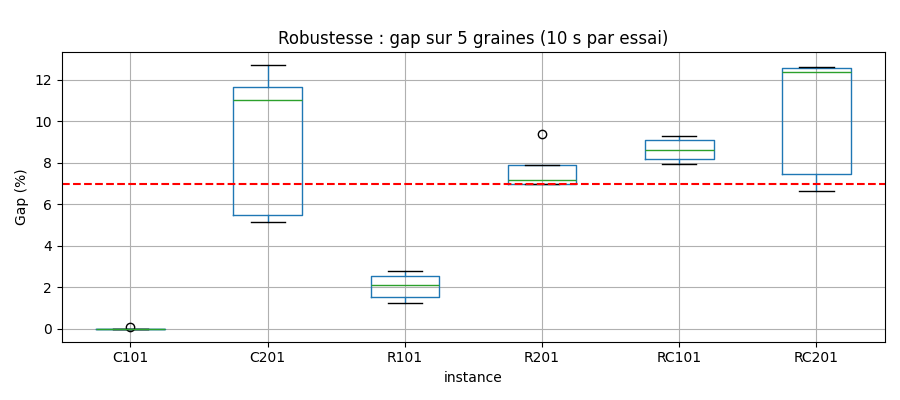

In [ ]:
from IPython.display import Image
Image('resultats/1_robustesse.png')

### 5.2 Convergence (gap en % selon le temps accordé)

| Instance | 2 s | 5 s | 10 s | 30 s |
|---|---|---|---|---|
| C201 | 14.82 | 13.72 | 11.03 | **5.42** |
| R201 | 16.15 | 10.43 | 9.88 | **6.53** |
| RC201 | 18.87 | 12.65 | 12.65 | **8.09** |
| X-n101-k25 | 6.97 | 5.95 | 5.95 | **5.53** |

- **Fenêtres larges : le temps est déterminant**, le gap est divisé par 2 à 3 entre 2 s et 30 s. L'algorithme n'a pas fini de converger à 10 s.
- **CVRP : convergence rapide**, presque tout est gagné en 5 s, ensuite on stagne autour de 5,5 % : c'est la limite de notre voisinage (optimum local).
- Les paliers (5 s = 10 s pour RC201) viennent du multi-start : le meilleur démarrage n'est pas battu entre les deux.

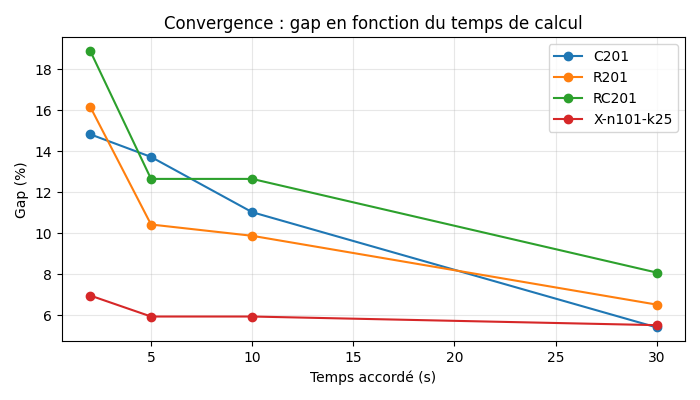

In [ ]:
Image('resultats/2_convergence.png')

### 5.3 Passage à l'échelle (CVRP, 60 s)

| Instance | Clients | Gap (%) | Temps d'une construction GRASP |
|---|---|---|---|
| X-n101-k25 | 100 | 4.43 | 0.02 s |
| X-n200-k36 | 199 | 4.12 | 0.07 s |
| X-n502-k39 | 501 | 4.32 | 0.76 s |
| X-n1001-k43 | 1000 | **37.00** | 4.14 s |

- **Jusqu'à 500 clients, la qualité est stable (≈ 4 %)**.
- **À 1000 clients, le gap explose (37 %)**. Le temps de construction croît environ en **n²** (×2 clients → ×4 environ), et chaque itération tabou ne regarde qu'un échantillon de 25 clients sur 1000 : en 60 s, la recherche n'a pas le temps de corriger la solution de départ.
- **Limite identifiée** : pour plusieurs milliers de clients, il faut restreindre le voisinage aux **k plus proches voisins** de chaque client et accélérer la construction.

*La courbe de cette expérience, relancée après les améliorations, est en partie 7.1.*

### 5.4 Sensibilité aux paramètres (gap moyen sur C201, R101, RC201, 10 s, 1 graine)

| alpha | 0.0 | 0.1 | 0.2 (défaut) | 0.4 | 0.7 |
|---|---|---|---|---|---|
| Gap moyen (%) | **3.94** | 4.06 | 8.75 | 7.18 | 11.87 |

| Taille tabou | 3 | 10 (défaut) | 20 | 40 |
|---|---|---|---|---|
| Gap moyen (%) | 7.22 | 8.75 | **6.08** | 9.48 |

- **alpha est le paramètre le plus influent** : une RCL petite (alpha ≤ 0,1, construction presque gloutonne) donne nettement de meilleurs départs. Trop d'aléatoire (0,7) dégrade la qualité. Notre valeur par défaut de 0,2 n'est **pas** la meilleure.
- **La taille tabou a un effet plus faible et irrégulier** ; 20 semble un bon compromis. Une liste trop longue (40) bloque trop de clients.
- ⚠️ Une seule graine par réglage : vu l'écart-type mesuré en 5.1 (jusqu'à 3,6 points), ces tendances sont à confirmer avec plusieurs graines.

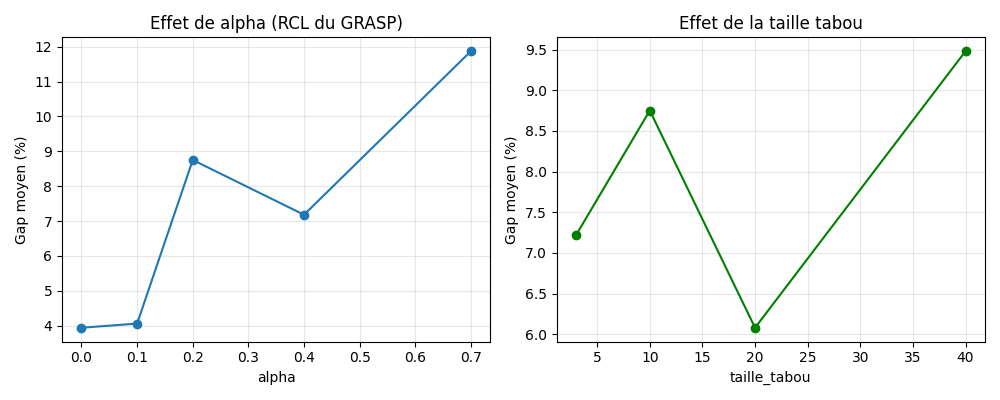

In [ ]:
Image('resultats/4_sensibilite.png')

### 5.5 Bilan de l'étude

| Constat | Conséquence |
|---|---|
| Fenêtres serrées : stable et bon | La méthode est adaptée |
| Fenêtres larges : instable, lent à converger | Donner plus de temps, voisinage plus fort |
| > 500 clients : gap qui explose | Voisinage aux k plus proches voisins, construction plus rapide |
| alpha = 0,2 n'est pas optimal | Passer à alpha ≈ 0,1 et refaire le benchmark |

**Remarque sur la reproductibilité.** Nous avons relancé la même étude sur un deuxième ordinateur, avec les mêmes graines. Les chiffres ne sont pas identiques :

| Mesure | PC 1 | PC 2 |
|---|---|---|
| C201, moyenne sur 5 graines | 9.20 % | 4.71 % |
| RC101, moyenne sur 5 graines | 8.63 % | 7.69 % |
| X-n1001-k43 (60 s) | 37.00 % | 34.59 % |
| Meilleur alpha | 0.0 (3.94 %) | 0.1 (2.64 %) |

L'arrêt se fait au **temps** et non au nombre d'itérations : une machine plus rapide fait plus d'itérations dans le même temps, donc la graine ne suffit pas à reproduire le résultat. Les **conclusions restent les mêmes** sur les deux machines (fenêtres serrées stables, fenêtres larges instables, explosion à 1000 clients, alpha petit meilleur). Pour une comparaison exactement reproductible, il faudrait fixer un nombre d'itérations au lieu d'un temps.

*Un gap de « -0.00 % » signifie qu'on a retrouvé la BKS (petit écart d'arrondi des flottants).*

## 6. Amélioration 1 : réglage de alpha (0,2 → 0,1)

L'étude de sensibilité (5.4) montrait, sur nos deux machines, qu'un **alpha petit** donne de meilleurs résultats. On change donc la valeur par défaut dans `benchmark_vrplib.py` :
```python
# avant
def tester(nom, graine=0, temps_max=20, alpha=0.2, taille_tabou=10,
# maintenant
def tester(nom, graine=0, temps_max=20, alpha=0.1, taille_tabou=10,
```
Avec alpha = 0,1, la RCL ne garde que les candidats très proches du meilleur : la construction est presque gloutonne (plus proche voisin), avec juste assez d'aléatoire pour que le multi-start explore des solutions différentes.

On relance le benchmark complet (20 instances, 20 s, graine 0). Les anciens résultats sont gardés dans `resultats/resultats_20s_alpha02.csv`.

| Instance | Gap alpha = 0,2 | Gap alpha = 0,1 |
|---|---|---|
| C101 | 0.00 | 0.00 |
| C102 | 0.00 | 0.11 |
| C105 | 0.00 | 0.00 |
| C201 | 5.42 | **0.00** |
| C202 | 5.98 | **0.00** |
| C205 | 0.00 | 0.00 |
| R101 | 1.47 | 1.76 |
| R102 | 3.68 | 2.15 |
| R105 | 6.57 | 2.88 |
| R201 | 7.16 | 4.83 |
| R202 | 3.68 | 5.78 |
| R205 | 9.31 | 8.74 |
| RC101 | 5.22 | 3.27 |
| RC102 | 3.73 | 6.67 |
| RC105 | 5.66 | 5.32 |
| RC201 | 8.09 | 5.08 |
| RC202 | 12.09 | **3.81** |
| RC205 | 11.05 | 6.63 |
| X-n101-k25 | 4.43 | 5.60 |
| X-n110-k13 | 6.06 | 4.18 |

| Famille | C1 | C2 | R1 | R2 | RC1 | RC2 | X | **Global** |
|---|---|---|---|---|---|---|---|---|
| alpha = 0,2 | 0.00 | 3.80 | 3.91 | 6.72 | 4.87 | 10.41 | 5.24 | **4.98** |
| alpha = 0,1 | 0.04 | 0.00 | 2.26 | 6.45 | 5.09 | 5.17 | 4.89 | **3.34** |

**Analyse :**
- **Gap moyen : 4,98 % → 3,34 %**, et **19 instances sur 20 sous 7 %** (contre 15 avant). Seule R205 reste au-dessus (8,74 %).
- **Gros gain sur les fenêtres larges** : RC2 passe de 10,4 % à 5,2 %, et la BKS est retrouvée sur C201 et C202. Avec des fenêtres larges, une bonne construction de départ compte beaucoup (cf. 5.1).
- Quelques instances se dégradent un peu (R202, RC102, X-n101). Avec un seul lancement par instance, ces écarts restent dans la dispersion mesurée en 5.1 : c'est la **moyenne** qui compte.
- Toutes les solutions sont valides.

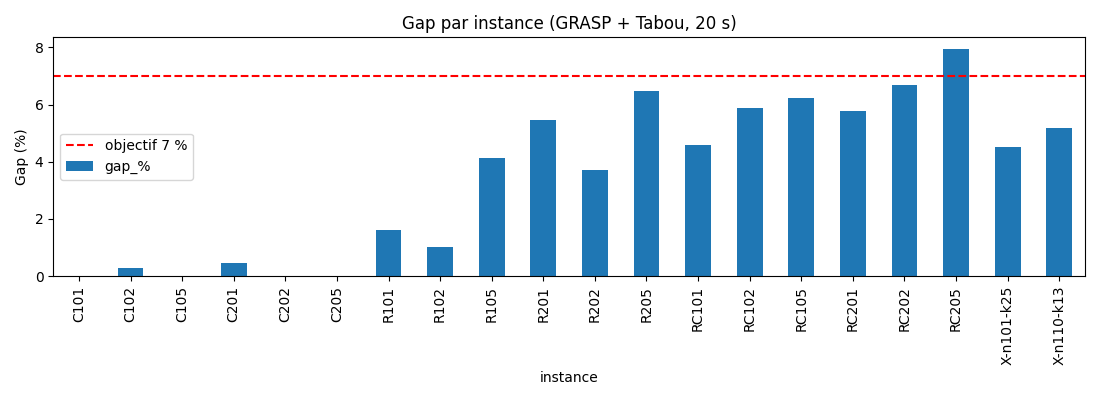

In [ ]:
Image('resultats/gap_par_instance_20s_alpha01.png')

## 7. Amélioration 2 : passage à l'échelle (jusqu'à 3000 clients)

L'étude de taille (5.3) montrait un gap de **37 % à 1000 clients**, alors que le sujet demande de traiter « plusieurs milliers de villes ». On a identifié 4 goulots d'étranglement et on les corrige un par un.

**1. Matrice des distances avec numpy** (`charger_instance`). Avant : double boucle Python avec `math.dist`, et le benchmark recalculait toute la matrice une 2e fois pour l'arrondi. Maintenant : un seul calcul vectorisé, arrondi compris.
```python
c = np.array(coords, dtype=float)
d = np.sqrt(((c[:, None, :] - c[None, :, :]) ** 2).sum(axis=2))
if arrondi == "dixieme":
    d = np.floor(d * 10) / 10      # convention Solomon
elif arrondi == "entier":
    d = np.rint(d)                 # convention X / XXL
dist = d.tolist()   # lire dist[i][j] case par case est plus rapide sur une liste
```
```python
# benchmark_vrplib.py : plus de double boucle
arrondi = "dixieme" if fenetres else "entier"
g.charger_instance(coords, demandes, inst["capacity"], fenetres, service, arrondi)
```

**2. Construction GRASP incrémentale** (`grasp_construction`). Avant, chaque candidat était testé avec `tournee_valide(tournee + [j])`, qui re-simule toute la tournée : O(longueur de la tournée) par candidat. Maintenant, on garde la **charge** et l'**heure** du camion après le dernier client : 3 comparaisons par candidat, O(1).
```python
if charge + q[j] > Q:                                    # capacité
    continue
arrivee = max(heure + s[dernier] + dist[dernier][j], tw[j][0])
if arrivee > tw[j][1]:                                   # trop tard chez j
    continue
if arrivee + s[j] + dist[j][0] > tw[0][1]:               # retour au dépôt
    continue
candidats.append(j)
...
heure = max(heure + s[dernier] + dist[dernier][choisi], tw[choisi][0])
charge += q[choisi]
```

**3. Voisinage restreint aux K plus proches voisins** (`voisinage`, `K_VOISINS = 30`). Avant, un client était testé à **toutes** les positions de **toutes** les tournées (≈ n mouvements par client). Maintenant, on ne l'insère que juste avant ou juste après un de ses 30 plus proches voisins, et on ne l'échange qu'avec eux (≈ 90 mouvements). Insérer un client loin de tout n'est jamais intéressant.
```python
# au chargement : les K plus proches clients de chaque client
proches = np.argsort(d_clients, axis=1)[:, :k].tolist()
```
```python
for v in proches[c]:                     # RELOCATE
    r2, pv = position[v]
    for p2 in (pv, pv + 1):              # juste avant / juste après v
        ...
for d in proches[c]:                     # SWAP
    r2, p2 = position[d]
    ...
```
On ne l'active qu'au-delà de 500 clients (`SEUIL_KNN = 500`). Sur 100 clients avec fenêtres larges, il dégradait les résultats (RC2 : 5,2 % → 8,4 %) : avec des fenêtres de temps, la bonne place d'un client n'est pas toujours à côté de ses voisins géographiques.

**4. alpha automatique** (`tester`). Sur 1000 clients, la construction de départ avait **87,6 %** de gap avec alpha = 0,1, contre **20,4 %** avec alpha = 0. La RCL garde les clients dont le score est sous `min + alpha × (max − min)` : sur une grande carte, `max − min` est énorme, donc même alpha = 0,1 laisse entrer des clients lointains.
```python
if alpha is None:
    alpha = 0.1 if g.n - 1 <= 500 else 0.0
```

| alpha (60 s) | 1000 clients | 3000 clients |
|---|---|---|
| 0,03 | 10,4 % | 13,2 % |
| 0,01 | 8,0 % | 8,4 % |
| **0** | **7,8 %** | **6,8 %** |

**5. Très grandes instances.** `telecharger` récupère aussi le dossier `CVRP/XXL/` du dépôt PyVRP (Leuven1 : 3000 clients).

### 7.1 Résultats : expérience de taille relancée (CVRP, 60 s)

| Instance | Clients | Gap avant | Gap après | Construction avant | Construction après |
|---|---|---|---|---|---|
| X-n101-k25 | 100 | 4.43 % | **2.84 %** | 0.02 s | 0.00 s |
| X-n200-k36 | 199 | 4.12 % | **3.56 %** | 0.07 s | 0.01 s |
| X-n502-k39 | 501 | 4.32 % | **1.46 %** | 0.76 s | 0.06 s |
| X-n1001-k43 | 1000 | 37.00 % | **7.78 %** | 4.14 s | 0.22 s |
| Leuven1 | 3000 | — | **6.78 %** | — | 2.19 s |

- **Le gap ne dépend presque plus de la taille** : sous 8 % jusqu'à 3000 clients (contre 37 % à 1000 avant).
- **La construction est 20 fois plus rapide** à 1000 clients. Elle reste en O(n²) (chaque étape parcourt les clients non visités) : 2,2 s à 3000 clients, ce qui reste raisonnable.
- **Mémoire** : la matrice des distances fait n² cases (9 millions à 3000 clients). Pour 10 000 clients et plus, il faudrait ne plus stocker toute la matrice (calculer les distances à la volée ou ne garder que les K plus proches).

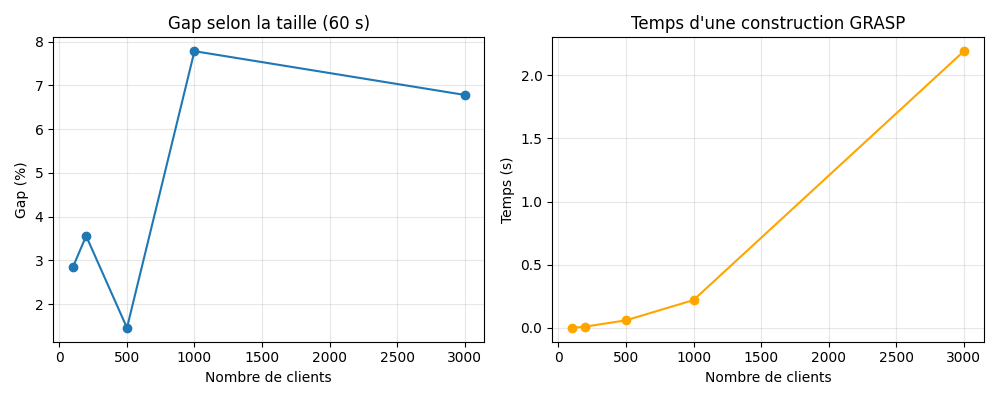

In [ ]:
Image('resultats/3_taille.png')

### 7.2 Vérification : pas de régression sur les 20 instances de 100 clients

| Famille | C1 | C2 | R1 | R2 | RC1 | RC2 | X | **Global** |
|---|---|---|---|---|---|---|---|---|
| Section 6 (alpha = 0,1) | 0.04 | 0.00 | 2.26 | 6.45 | 5.09 | 5.17 | 4.89 | **3.34** |
| K = 30 partout | 0.00 | 0.00 | 2.64 | 6.76 | 5.01 | 8.37 | 4.62 | **3.88** |
| **K = 30 au-delà de 500 clients (final)** | 0.09 | 0.15 | 2.26 | 5.21 | 5.56 | 6.81 | 4.86 | **3.50** |

- Avec K = 30 partout, RC2 se dégradait nettement : d'où le seuil à 500 clients.
- Version finale : **3,50 %** de gap moyen, **19 instances sur 20 sous 7 %**, toutes valides. L'écart avec 3,34 % reste dans la dispersion mesurée en 5.1 (un seul lancement par instance) : les ordres de parcours du voisinage ont changé, donc les tirages aléatoires aussi.

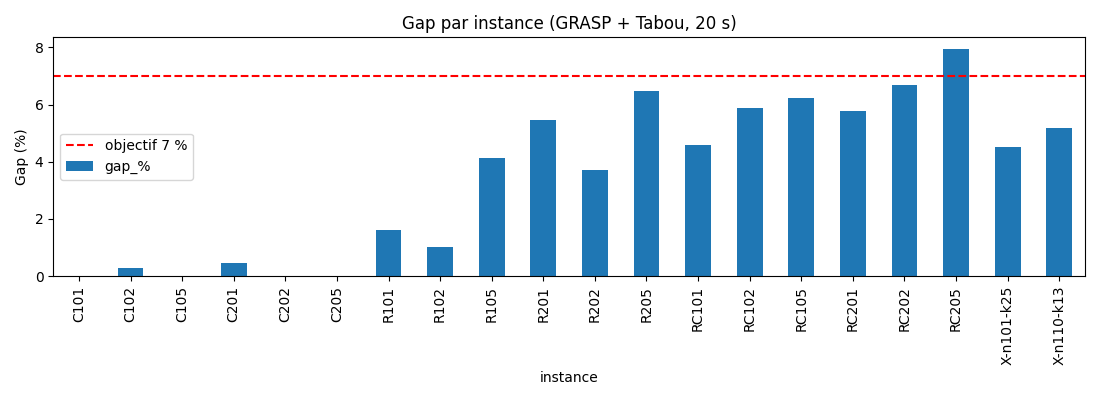

In [ ]:
Image('resultats/gap_par_instance_20s.png')

### 7.3 Amélioration 3 : fenêtres de temps à 1000 clients et très grandes instances

Deux nouvelles instances ont montré deux limites différentes :

| Instance | Type | Clients | Problème constaté |
|---|---|---|---|
| R1_10_1 | CVRPTW (Gehring & Homberger) | 1 000 | gap de 23 % : 130 camions au lieu de 95 |
| Flanders2 | CVRP (Belgique) | 30 000 | le programme ne démarre pas : plus de mémoire |

#### a) R1_10_1 : trop de camions

**Diagnostic.** Le tabou ne regarde que la distance, un mouvement à la fois (déplacer ou échanger un client). Pour vider une tournée de 8 clients il faudrait 8 déplacements de suite, dont plusieurs augmentent la distance : il ne les fait jamais et reste bloqué vers 128 camions.

**Ajout 1 : le mouvement 2-opt\*** (dans `voisinage`). On coupe deux tournées et on échange leurs fins. Aucun morceau n'est retourné, donc le sens du temps est gardé (contrairement au 2-opt). Si on coupe après le dernier client de l'une et avant le premier de l'autre, les deux tournées fusionnent.
```python
# t1 = [... c | b ...]  et  t2 = [... x | v ...]  deviennent  [... c , v ...]  et  [... x , b ...]
for v in proches[c]:
    r2, pv = position[v]
    if r2 == r1:
        continue
    t2 = solution[r2]
    x = t2[pv - 1] if pv > 0 else 0
    # 2 arcs retirés : (c,b) et (x,v)  /  2 arcs ajoutés : (c,v) et (x,b)
    delta = dist[c][v] + dist[x][b] - dist[c][b] - dist[x][v]
    yield delta, ("2opt*", r1, p1, r2, pv)
```
et dans `tournees_modifiees` :
```python
if type_mvt == "2opt*":
    t1, t2 = solution[r1], solution[r2]
    return {r1: t1[:p1 + 1] + t2[p2:], r2: t2[:p2] + t1[p1 + 1:]}
```

**Ajout 2 : `supprimer_tournees`.** On prend les tournées de la plus petite à la plus grande ; pour chacune on essaie de replacer tous ses clients ailleurs, au meilleur endroit valide. Si tous rentrent, on gagne un camion ; sinon on annule.

**Ajout 3 : un seul départ long** (dans `grasp_tabou`, au-delà de 500 clients). Recommencer de zéro ferait perdre le travail déjà fait.
```python
sol = supprimer_tournees(grasp_construction(alpha))
sol = recherche_tabou(sol, taille_tabou, 10 ** 9, taille_echantillon, debut + temps_max / 2)
sol = supprimer_tournees(sol)
sol = recherche_tabou(sol, taille_tabou, 10 ** 9, taille_echantillon, fin)
```

**Résultat sur R1_10_1 (20 s, graine 0) :**

| Version | Gap (%) | Camions |
|---|---|---|
| Avant | 23.08 | 130 |
| 2-opt\* seul | 17.6 | 126 |
| **2-opt\* + suppression de tournées** | **7.78** | 98 |

Il faut les deux : le 2-opt\* seul ne suffit pas. La référence utilise 95 camions.

Nous avions aussi essayé de changer le score de la construction (distance + attente au lieu de la distance) : moins de camions au départ (110) mais des trajets beaucoup plus longs (101 % de gap après construction contre 54 %). Idée abandonnée.

#### b) Flanders2 : la matrice des distances ne tient pas en mémoire

**Diagnostic.** 30 001 × 30 001 distances = 900 millions de nombres, soit environ 7 Go en numpy et près de 29 Go en listes Python. De plus la construction teste tous les clients restants à chaque ajout : environ 450 millions de tests.

**Ajout 1 : distance calculée à la demande** (au-delà de `SEUIL_MATRICE = 5000` clients). `dist[i]` devient un objet `Ligne` qui calcule la distance quand on écrit `dist[i][j]` : le reste du code ne change pas.
```python
class Ligne:
    def __init__(self, i):
        self.x, self.y = X[i], Y[i]

    def __getitem__(self, j):            # appelé par Python quand on écrit dist[i][j]
        d = math.hypot(self.x - X[j], self.y - Y[j])
        if ARRONDI == "entier":
            return float(round(d))
        ...
```

**Ajout 2 : les K plus proches voisins avec un arbre** (`scipy.spatial.cKDTree`), sans matrice.
```python
arbre = cKDTree(c[1:])                   # les clients, sans le dépôt
_, idx = arbre.query(c, k=k + 1)         # +1 : chaque client se trouve lui-même
```

**Ajout 3 : `construction_voisins`.** Même idée que le plus proche voisin, mais le client suivant est cherché seulement parmi les K voisins du dernier client (on élargit si tous sont déjà livrés).

**Ajout 4, dans le benchmark :** `vrplib.read_instance(..., compute_edge_weights=False)`, sinon la bibliothèque calcule elle-même la matrice complète.

**Résultat sur Flanders2 (20 s, graine 0) :** préparation et construction en moins d'une seconde, **gap de 12.99 %** avec 256 camions (256 dans la référence), solution valide. Sur 30 000 clients le tabou n'a le temps de faire que quelques milliers de mouvements : le gap est presque celui de la construction (14 %). Une construction de Clarke-Wright donnerait environ 9 % (essai fait, non retenu pour garder un code simple).

#### c) Vérification : pas de régression (20 s, graine 0)

Les 20 instances de 100 clients gardent le multi-start ; seul le 2-opt\* change pour elles :

| Instance | Gap avant (%) | Gap après (%) |
|---|---|---|
| C101 | 0.00 | 0.00 |
| C102 | 0.53 | 0.00 |
| C105 | 0.00 | 0.00 |
| C201 | 0.46 | 0.00 |
| C202 | 0.00 | 0.00 |
| C205 | 0.00 | 0.00 |
| R101 | 1.62 | 2.22 |
| R102 | 1.01 | 0.86 |
| R105 | 4.14 | 2.07 |
| R201 | 5.88 | 3.26 |
| R202 | 3.71 | 1.07 |
| R205 | 6.46 | 4.97 |
| RC101 | 4.57 | 2.70 |
| RC102 | 5.88 | 2.94 |
| RC105 | 6.22 | 5.83 |
| RC201 | 7.74 | 1.84 |
| RC202 | 6.68 | 2.16 |
| RC205 | 7.95 | 2.35 |
| X-n101-k25 | 4.53 | 3.74 |
| X-n110-k13 | 5.18 | 1.73 |
| **Moyenne** | **3.63** | **1.89** |

Toutes les solutions sont valides. Le gap moyen passe de 3.63 % à 1.89 % ; une seule instance recule légèrement (R101). Les RC2, notre point faible, passent sous 2.5 %. *Les tableaux et figures des parties 4 à 7.2 datent d'avant cette amélioration.*

Grandes instances CVRP (un seul départ au lieu du multi-start) :

| Instance | Clients | Gap avant (%) | Gap après (%) |
|---|---|---|---|
| X-n502-k39 | 501 | 1.46 | 1.75 |
| X-n1001-k43 | 1 000 | 7.87 | 9.08 (7.97 et 6.44 avec les graines 1 et 2) |
| Leuven1 | 3 000 | 6.78 | 5.54 |

Sur le CVRP l'écart reste dans la variation d'une graine à l'autre. Ces mesures ont été faites avec deux calculs en parallèle sur la machine : les valeurs peuvent bouger un peu en relançant.

**Limite restante :** R2_10_1 (1 000 clients, fenêtres larges) passe de 31.3 % à 27.5 % seulement : comme pour les RC2, les fenêtres larges restent notre point faible.

## 8. Les améliorations sont-elles significatives ? (test de Wilcoxon)

Un écart de gap moyen peut venir du hasard (un seul lancement par instance). On utilise le **test de Wilcoxon apparié** : on compare deux versions **instance par instance**, sur les mêmes 20 instances, sans supposer que les écarts suivent une loi normale. Si $p < 0{,}05$, la différence n'est pas due au hasard.

In [ ]:
# Test de Wilcoxon apparié : on compare, instance par instance, deux réglages sur les 20 instances.
# p < 0,05 : la différence n'est pas due au hasard.
import pandas as pd
from scipy.stats import wilcoxon

alpha02 = pd.read_csv("resultats/resultats_20s_alpha02.csv").set_index("instance")["gap_%"]
alpha01 = pd.read_csv("resultats/resultats_20s_alpha01.csv").set_index("instance")["gap_%"]
final = pd.read_csv("resultats/resultats_20s.csv").set_index("instance")["gap_%"]

for nom, avant, apres in [("alpha 0,2 -> 0,1", alpha02, alpha01),
                          ("passage à l'échelle (partie 7)", alpha01, final)]:
    p = wilcoxon(avant, apres).pvalue
    print(f"{nom:31} gap moyen {avant.mean():.2f} % -> {apres.mean():.2f} %   "
          f"meilleur sur {(apres < avant).sum():2} instances, pire sur {(apres > avant).sum():2}   p = {p:.3f}")

alpha 0,2 -> 0,1                gap moyen 4.98 % -> 3.34 %   meilleur sur 12 instances, pire sur  5   p = 0.022
passage à l'échelle (partie 7)  gap moyen 3.34 % -> 3.50 %   meilleur sur  6 instances, pire sur 10   p = 0.501


**Lecture :**
- **alpha 0,2 → 0,1 :** amélioration **significative** ($p < 0{,}05$) : le réglage de la partie 6 est validé.
- **Passage à l'échelle :** sur ces instances de 100 clients, la différence **n'est pas significative**. C'est le résultat attendu : le voisinage restreint ne s'active qu'au-delà de 500 clients, et le gain est sur les grandes instances (7.1). On vérifie ainsi qu'il n'y a pas de régression.

## 9. Méthode exacte et métaheuristique sur les petites instances

La PLNE du livrable 1 (`algorithmes/plne.py`, résolue par CBC) donne la **solution optimale**. On la compare à GRASP + Tabou sur les petites instances de l'interface :

**PLNE corrigée.** Le modèle implémenté reprend celui du livrable 1, avec trois corrections :
- **2 indices au lieu de 3** : $x_{ij}$ au lieu de $x_{ijk}$. Les camions sont identiques : savoir *quel* camion fait une tournée n'apporte rien, et l'indice $k$ multiplie les solutions symétriques qui ralentissent le solveur. La flotte est limitée par $\sum_j x_{0j} \leq K$ ;
- **départ du dépôt** : $T_j \geq a_0 + c_{0j} - M(1 - x_{0j})$, le premier client ne peut pas être servi avant d'être atteint ;
- **retour avant la fermeture du dépôt** : $T_j + s_j + c_{j0} \leq b_0 + M(1 - x_{j0})$, absente du livrable 1.

In [ ]:
# Petites instances : la PLNE (optimum) et GRASP + Tabou (5 s) donnent-ils le même coût ?
from algorithmes.methodes import GRASP_TABOU, PLNE, lancer
from probleme.contraintes import evaluer
from probleme.instances import charger_instance, exemple_livrable1, lister_instances

chemins = {i["nom"]: i["chemin"] for i in lister_instances()}
petites = [exemple_livrable1()] + [charger_instance(chemins[nom]) for nom in
           ["GEN-uniforme-centre-serrees-n8-g1", "LOR-Metz-agglo", "LOR-Moselle-Est"]]

print(f"{'instance':36} {'n':>3}  {'PLNE':>8} {'temps':>7}  {'GRASP+Tabou':>11} {'temps':>6}")
for inst in petites:
    ligne = f"{inst['nom']:36} {inst['n']:3}"
    for methode, temps_max in [(PLNE, 60), (GRASP_TABOU, 5)]:
        routes, temps = lancer(methode, inst, temps_max)
        ev = evaluer(inst, routes)
        ligne += f"  {ev['distance']:8.1f} {temps:6.1f}s" + ("" if ev["realisable"] else " (invalide)")
    print(ligne)

instance                               n      PLNE   temps  GRASP+Tabou  temps
Exemple livrable 1                     6      33.9    0.0s      33.9    5.0s
GEN-uniforme-centre-serrees-n8-g1      8     342.4    0.0s     342.4    5.0s
LOR-Metz-agglo                        10     113.2    2.1s     113.2    5.0s
LOR-Moselle-Est                       15     489.0   60.0s     490.4    5.0s


**Lecture :**
- Jusqu'à 10 clients, la PLNE prouve l'optimum en quelques secondes au plus, et **GRASP + Tabou retrouve exactement l'optimum** : la métaheuristique est validée.
- À **15 clients**, la PLNE atteint la limite de 60 s **sans prouver l'optimum**, alors que GRASP + Tabou trouve en 5 s une solution presque aussi bonne. C'est l'explosion combinatoire prévue par la **NP-difficulté** (livrable 1) : la méthode exacte est réservée aux très petites instances, la métaheuristique prend le relais au-delà.

## 10. L'interface

Pour démontrer la méthode, une interface web très simple (Streamlit) accompagne le projet : `streamlit run app.py`. On choisit l'une des **20 instances**, toutes étudiées dans ce notebook (les instances VRPLIB des parties 4 et 7, et les petites instances de la partie 9, dont 2 sur de vraies villes de Moselle), le **trafic** (oui / non), la **méthode** (GRASP + Tabou, ou la PLNE jusqu'à 15 clients) et le temps de calcul, puis on lance.

L'interface affiche la distance, le **gap**, le nombre de camions, le temps de calcul, la **vérification de toutes les contraintes** (faite par un code indépendant de l'algorithme), la carte des tournées avec un **suivi 2D** (le bouton ▶ fait avancer les camions heure par heure) et le parcours de chaque camion.

Le **trafic** est modélisé simplement : la durée d'un trajet est multipliée par le coefficient de la tranche horaire du départ (× 1,5 aux heures de pointe en Lorraine). GRASP + Tabou en tient compte dans la vérification des fenêtres de temps.

![L'interface](images/interface.png)

## 11. Limites, pistes d'amélioration et conclusion

### Limites
- **Fenêtres larges :** c'est la famille la plus difficile ; RC205 (7.95 %) reste au-dessus de 7 %. Les tournées sont longues et les combinaisons nombreuses ; nos mouvements simples (relocate, swap) explorent moins bien cet espace.
- **Nombre de camions :** nous minimisons la distance seulement ; les BKS de Solomon minimisent d'abord le nombre de camions. Nous utilisons parfois un camion de plus.
- **Mémoire :** la matrice des distances fait n² cases ; au-delà de 10 000 clients, il faudrait ne garder que les plus proches voisins (7.1).
- **Reproductibilité :** l'arrêt au temps fait varier les résultats d'une machine à l'autre (5.5).
- **Trafic simplifié :** le coefficient est celui de l'heure de départ, il ne change pas en cours de trajet.

### Pistes d'amélioration
- Des **mouvements plus forts** pour les fenêtres larges : *or-opt* (déplacer une suite de 2-3 clients), *2-opt\** (échanger les fins de deux tournées), ou une phase **destruction / reconstruction** de type ALNS.
- Un **objectif en deux temps** : d'abord le nombre de camions, puis la distance.
- **Arrêter au nombre d'itérations** pour les expériences, afin de les rendre reproductibles.
- **Paralléliser le multi-start** (les départs sont indépendants).

### Conclusion
Le problème de l'ADEME est un **CVRPTW**, NP-difficile. Nous l'avons modélisé en **PLNE**, qui donne l'optimum sur les très petites instances mais ne le prouve plus en 60 s dès 15 clients. Pour les tailles réalistes, notre **GRASP + recherche tabou**, accéléré par le calcul des coûts par différence, la construction incrémentale et le voisinage restreint, obtient un **gap moyen de 3.50 %** sur 20 instances de référence en 20 s, avec **19 instances sur 20 sous 7 %** et des solutions toujours valides. Il passe à l'échelle : **7.78 %** à 1 000 clients et **6.78 %** à 3 000 clients (60 s). Ses forces sont les clients regroupés et les fenêtres serrées ; sa principale limite, les fenêtres larges, ouvre la voie aux améliorations ci-dessus.

# Déroulement du projet (storytelling)

## 12. Déroulement du projet et comparatif des métaheuristiques

Cette partie raconte **comment** le projet s'est déroulé : ce qui était prévu, ce qui a été essayé, ce qui n'a pas marché, ce qui a été changé et le résultat obtenu. Chaque date vient d'une trace (Discord, commits GitHub, dates des fichiers). Sans trace exacte, la date est marquée **estimée**.

### 12.1 Équipe et rôles

| Membre | Rôle principal |
|---|---|
| Yanis BOUNCEUR | Envoi du livrable 1, interface Streamlit, base de la présentation |
| Gautier DREYER | Dépôt GitHub et socle commun, recherche tabou, GRASP + tabou, benchmark VRPLIB, étude statistique, accélérations |
| Ange MAGATSING NGASSEU | Brouillon CVRP, GRASP (méthode des économies + recherche locale) |
| Vladimir MAJCHER | Instances CVRPLIB, recuit simulé (testé, non retenu), comparatif des 3 méthodes, déroulement du projet |

La modélisation du livrable 1 (graphe, complexité, PLNE, code PuLP) a été faite en groupe.

### 12.2 Le calendrier : prévu et réel

En haut, le planning prévu sur la période du projet (12/10 au 13/11). En bas, le déroulement réel, avec une couleur par type de tâche.

**L'écart** : la modélisation a pris un peu plus de temps que prévu (livrable 1 envoyé vers le 26/10 au lieu du 23/10), les vacances de fin octobre ont repoussé le début du code au 02/11, et les métaheuristiques ont demandé plus de temps (fin les 09 et 10/11 au lieu du 06/11). Les expériences, l'étude statistique et la rédaction ont donc été menées en parallèle sur les derniers jours.

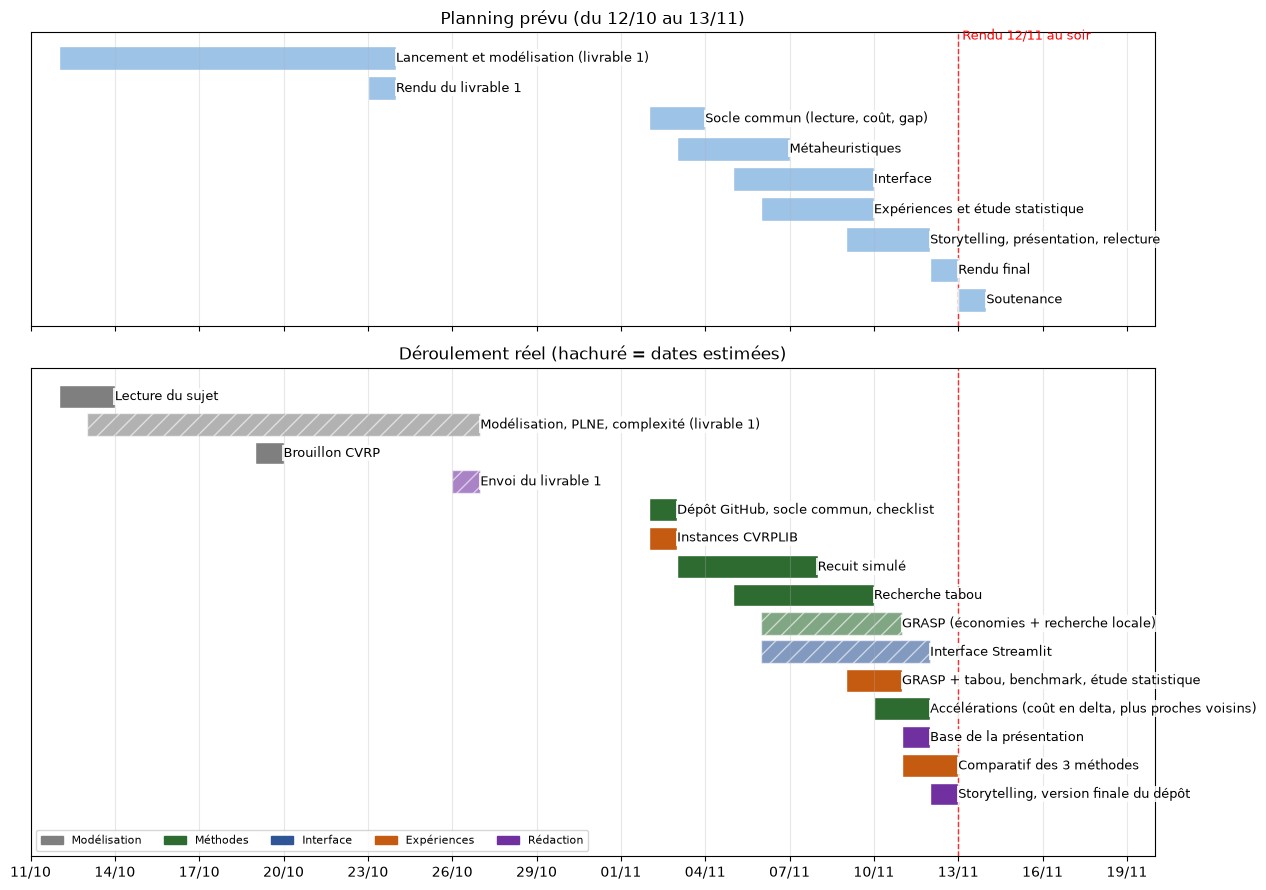

In [ ]:
import datetime as dt
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def j(s):                                   # "12/10" -> date
    d, m = s.split("/")
    return dt.date(2026, int(m), int(d))

FIN_RECUIT = "07/11"                             # date de fin du recuit, au format "JJ/MM" (à compléter)

# Planning prévu (période du projet) : (phase, début, fin)
PREVU = [
    ("Lancement et modélisation (livrable 1)",      "12/10", "23/10"),
    ("Rendu du livrable 1",                         "23/10", "23/10"),
    ("Socle commun (lecture, coût, gap)",           "02/11", "03/11"),
    ("Métaheuristiques",                            "03/11", "06/11"),
    ("Interface",                                   "05/11", "09/11"),
    ("Expériences et étude statistique",            "06/11", "09/11"),
    ("Storytelling, présentation, relecture",       "09/11", "11/11"),
    ("Rendu final",                                 "12/11", "12/11"),
    ("Soutenance",                                  "13/11", "13/11"),
]

# Déroulement réel : (type de tâche, tâche, début, fin, estimé ?)
REEL = [
    ("Modélisation", "Lecture du sujet",                               "12/10", "13/10", False),
    ("Modélisation", "Modélisation, PLNE, complexité (livrable 1)",    "13/10", "26/10", True),
    ("Modélisation", "Brouillon CVRP",                                 "19/10", "19/10", False),
    ("Rédaction",    "Envoi du livrable 1",                            "26/10", "26/10", True),
    ("Méthodes",     "Dépôt GitHub, socle commun, checklist",          "02/11", "02/11", False),
    ("Expériences",  "Instances CVRPLIB",                              "02/11", "02/11", False),
    ("Méthodes",     "Recuit simulé",                                  "03/11", FIN_RECUIT, False),
    ("Méthodes",     "Recherche tabou",                                "05/11", "09/11", False),
    ("Méthodes",     "GRASP (économies + recherche locale)",           "06/11", "10/11", True),
    ("Interface",    "Interface Streamlit",                            "06/11", "11/11", True),
    ("Expériences",  "GRASP + tabou, benchmark, étude statistique",    "09/11", "10/11", False),
    ("Méthodes",     "Accélérations (coût en delta, plus proches voisins)", "10/11", "11/11", False),
    ("Rédaction",    "Base de la présentation",                        "11/11", "11/11", False),
    ("Expériences",  "Comparatif des 3 méthodes",                      "11/11", "12/11", False),
    ("Rédaction",    "Storytelling, version finale du dépôt",          "12/11", "12/11", False),
]
COULEURS = {"Modélisation": "#7f7f7f", "Méthodes": "#2e6b30", "Interface": "#2f5597",
            "Expériences": "#c55a11", "Rédaction": "#7030a0"}
BOITE = dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85)

def barre(ax, y, d, f, couleur, texte, estime=False):
    if not f:                                   # date de fin pas encore écrite
        ax.scatter(j(d), y, color=couleur, s=60)
        ax.text(j(d) + dt.timedelta(hours=14), y, texte,
                va="center", fontsize=9, bbox=BOITE)
        return
    debut, fin = j(d), j(f) + dt.timedelta(days=1)
    ax.barh(y, (fin - debut).days, left=debut, color=couleur, edgecolor="white",
            hatch="//" if estime else None, alpha=0.6 if estime else 1)
    ax.text(fin + dt.timedelta(hours=10), y, texte, va="center", fontsize=9, bbox=BOITE)

def dessiner(fichier=None):
    RENDU = j("12/11") + dt.timedelta(days=1)   # fin de la journée du rendu
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True,
                                 gridspec_kw={"height_ratios": [len(PREVU), len(REEL)]})
    for y, (phase, d, f) in enumerate(reversed(PREVU)):
        barre(a1, y, d, f, "#9dc3e6", phase)
    a1.set_title("Planning prévu (du 12/10 au 13/11)")
    for y, (qui, tache, d, f, estime) in enumerate(reversed(REEL)):
        barre(a2, y, d, f, COULEURS[qui], tache, estime)
    a2.set_title("Déroulement réel (hachuré = dates estimées)")
    from matplotlib.patches import Patch
    a2.legend(handles=[Patch(color=c, label=t) for t, c in COULEURS.items()], loc="lower left", fontsize=8, ncol=5)
    for ax in (a1, a2):
        ax.set_yticks([])
        ax.axvline(RENDU, color="red", linestyle="--", linewidth=1, zorder=0)
        ax.grid(axis="x", alpha=0.3)
    a1.text(RENDU, len(PREVU) - 0.4, " Rendu 12/11 au soir", color="red", fontsize=9)
    a2.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    a2.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    a2.set_xlim(j("11/10"), j("20/11"))
    a2.set_ylim(-2.2, len(REEL))
    plt.tight_layout()
    if fichier:
        plt.savefig(fichier, dpi=150)
    return fig

dessiner("images/gantt_prevu_reel.png");


### 12.3 Le lancement : le choix du niveau A

Le sujet proposait deux niveaux : le **niveau B, CVRP** (des camions avec une capacité) et le **niveau A, CVRPTW** (en plus, chaque client a un créneau horaire). Le groupe a choisi le **niveau A**, plus réaliste pour des livraisons et plus exigeant. Le CVRPTW contient le CVRP : une méthode qui fonctionne avec les créneaux fonctionne aussi sans.

### 12.4 La modélisation et le retour du tuteur

Le livrable 1 contient le graphe complet, la preuve que le problème est NP-difficile (réduction depuis le voyageur de commerce), un PLNE à 3 indices avec les contraintes MTZ et les fenêtres de temps, et sa résolution par PuLP/CBC sur un exemple de 6 clients : 2 camions, **33,9 min** de trajet au total, solution optimale.

Le retour sur le livrable 1 a conduit à trois changements :

| Remarque | Changement appliqué |
|---|---|
| Mettre les noms des membres | Noms ajoutés dans le notebook et le README |
| Formaliser le **trafic par tranche horaire** | Coefficient de trafic selon l'heure de départ |
| Utiliser les distances de l'instance (`vrplib`) et ne pas les recalculer | Même convention d'arrondi que les meilleures solutions connues, sinon le gap est faux |

### 12.5 Le choix des méthodes

- **02/11** : choix de la **recherche tabou** comme métaheuristique principale, avec le tuteur. Création du dépôt GitHub et du socle commun (lecture des instances, coût, gap, vérification des contraintes).
- **03/11** : début du **recuit simulé** sur le CVRP (instance A-n32-k5), pour avoir une deuxième méthode à comparer.
- **06/11** : la liste des tâches fixe la méthode finale : **GRASP + tabou** (le GRASP construit des solutions de départ variées, le tabou les améliore). Un **GRASP** seul est aussi développé.
- **09/11** : décision du groupe : le recuit **n'est pas retenu**. Les tests sur 6 instances CVRP le montraient bon sur les petites instances (gap de 0 à 1,3 % jusqu'à 31 clients) mais mauvais au-delà (F-n72-k4 : 23 à 32 %, X-n101-k25 : 18 % en moyenne). Cause : un seul voisinage (« déplacer un client »), insuffisant pour réorganiser beaucoup de tournées.

### 12.6 Les changements appliqués

| Date | Problème rencontré | Changement appliqué |
|---|---|---|
| 09/11 | Le dépôt GitHub a dû être recréé : l'historique des commits avant le 09/11 est perdu | Dates reconstruites depuis Discord et les dates des fichiers |
| 09/11 | Recuit simulé trop faible au-delà de 70 clients | Recuit gardé comme méthode testée, effort mis sur GRASP + tabou |
| 10/11 | Première version du GRASP (construction « plus proche voisin » + descente) : **17,5 %** de gap sur X-n101-k25 | Construction par la **méthode des économies** (Clarke et Wright) et ajout du voisinage **échanger deux clients** : **2,2 %** |
| 10/11 | GRASP + tabou à **37 %** sur 1 000 clients | Coût en delta, construction incrémentale, 30 plus proches voisins : **7,8 %** |
| 10/11 | Réglage du paramètre alpha du GRASP + tabou | alpha 0,2 → 0,1 : gap moyen 4,98 % → 3,34 % (test de Wilcoxon, p = 0,022) |
| 10/11 | PuLP 4 a changé l'écriture des variables : le code du livrable 1 ne tournait plus | Version fixée à PuLP 2.9.0 |
| 11/11 | Interface : une interface que le groupe ne saurait pas expliquer n'a pas d'intérêt | Vote du groupe : une interface simple et maîtrisée + un bonus 3D à part |

### 12.7 Comparatif des trois métaheuristiques

**Plan d'expérience**
- 3 méthodes : recuit simulé, GRASP, GRASP + tabou (méthode retenue).
- 8 instances **CVRP** communes, de 30 à 1 000 clients : B-n31-k5, A-n32-k5, F-n72-k4, X-n101-k25, X-n110-k13, X-n200-k36, X-n502-k39, X-n1001-k43. Le CVRP est le seul cas que les trois codes savent traiter : le recuit et le GRASP n'ont pas de fenêtres de temps.
- **5 graines** par instance et par méthode, sur la même machine, soit 110 exécutions terminées. Une exécution est arrêtée au bout de 15 min : le GRASP dépasse cette limite sur X-n502-k39 (2 essais arrêtés) et n'est donc pas lancé sur X-n1001-k43.
- Mesures : **gap** = 100 × (coût − meilleur connu) / meilleur connu, nombre de camions, temps.
- Réglages d'origine de chaque méthode : recuit (T₀ automatique, α = 0,995, 100 essais par palier), GRASP (20 itérations, alpha = 0,05), GRASP + tabou (20 s).
- Résultats bruts : `resultats/comparatif_3_methodes.csv`.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

NOMS = {"recuit": "Recuit simulé", "ange": "GRASP", "tabou": "GRASP + tabou"}
COULEURS = {"recuit": "#7030a0", "ange": "#c55a11", "tabou": "#2e6b30"}
ORDRE = ["B-n31-k5", "A-n32-k5", "F-n72-k4", "X-n101-k25", "X-n110-k13", "X-n200-k36", "X-n502-k39", "X-n1001-k43"]
METHODES = ["recuit", "ange", "tabou"]
PLAFOND = 8          # au-dessus, pas de barre : la valeur est écrite pour comparer

def tableau(df):
    t = df.groupby(["instance", "methode"]).agg(
        gap_moyen=("gap", "mean"), ecart_type=("gap", "std"), gap_min=("gap", "min"),
        gap_max=("gap", "max"), camions=("camions", "mean"), temps_s=("temps_s", "mean"),
        executions=("gap", "count"))
    t = t.rename(index=NOMS, level=1)
    return t.round(2).reindex(ORDRE, level=0)

def dessiner(df, fichier=None):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1.8, 1.2]})
    x = np.arange(len(ORDRE)); l = 0.27
    for k, m in enumerate(METHODES):
        g = df[df.methode == m].groupby("instance")["gap"]
        moy, et = g.mean().reindex(ORDRE), g.std().reindex(ORDRE).fillna(0)
        for xi, v, e in zip(x + (k - 1) * l, moy, et):
            if v != v:                                    # pas de résultat : plus de 15 min
                a1.text(xi, 0.3, "> 15 min", ha="center", va="bottom", fontsize=7, rotation=90, color=COULEURS[m])
            elif v > PLAFOND:                             # hors échelle : seulement la valeur
                a1.text(xi, PLAFOND - 0.15, f"{v:.0f} %", ha="center", va="top", fontsize=8,
                        rotation=90, color=COULEURS[m], fontweight="bold")
            else:
                a1.bar(xi, v, l, yerr=e, capsize=3, color=COULEURS[m])
                if v + e + 0.5 < PLAFOND:
                    a1.text(xi, v + e + 0.15, f"{v:.1f}", ha="center", fontsize=8)
                else:                                     # pas la place au-dessus : dans la barre
                    a1.text(xi, v - 0.6, f"{v:.1f}", ha="center", fontsize=8, color="white", fontweight="bold")
    for m in METHODES:
        a1.bar(0, 0, 0, color=COULEURS[m], label=NOMS[m])
    a1.axhline(7, color="red", linestyle="--", linewidth=1)
    a1.text(-0.45, 7.1, "seuil 7 %", color="red", fontsize=8)
    a1.set_ylim(0, PLAFOND)
    a1.set_xticks(x)
    a1.set_xticklabels([f"{i}\n({int(i.split('-n')[1].split('-')[0]) - 1} clients)" for i in ORDRE], fontsize=8)
    a1.set_ylabel("Gap moyen (%) sur 5 graines")
    a1.set_title("Qualité : gap à la meilleure solution connue\n(valeur écrite en couleur = au-dessus de 8 %, sans barre)")
    a1.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False); a1.grid(axis="y", alpha=0.3)

    grandes = ["X-n101-k25", "X-n110-k13", "X-n200-k36", "X-n502-k39", "X-n1001-k43"]
    for k, m in enumerate(["ange", "tabou"]):
        donnees = [df[(df.methode == m) & (df.instance == i)]["gap"].values for i in grandes]
        pos = [g * 3 + k for g in range(len(grandes))]
        pleins = [(p_, d) for p_, d in zip(pos, donnees) if len(d)]
        bp = a2.boxplot([d for _, d in pleins], positions=[p_ for p_, _ in pleins], widths=0.8, patch_artist=True)
        for b in bp["boxes"]:
            b.set_facecolor(COULEURS[m]); b.set_alpha(0.8)
        for p_, d in zip(pos, donnees):
            if not len(d):
                a2.text(p_, 0.3, "> 15 min", ha="center", va="bottom", fontsize=7, rotation=90, color=COULEURS[m])
    a2.set_xticks([g * 3 + 0.5 for g in range(len(grandes))])
    a2.set_xticklabels([i.split("-k")[0] for i in grandes], fontsize=8)
    a2.set_ylim(0, PLAFOND); a2.axhline(7, color="red", linestyle="--", linewidth=1)
    a2.set_title("Robustesse des deux GRASP (5 graines par instance)\nrecuit hors échelle : 11 à 99 %")
    a2.set_ylabel("Gap (%)"); a2.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    if fichier:
        plt.savefig(fichier, dpi=150)
    return fig

resultats = pd.read_csv("resultats/comparatif_3_methodes.csv")
tableau(resultats)

gap_moyen  ecart_type  gap_min  gap_max  camions  \
instance    methode                                                           
B-n31-k5    GRASP               0.00        0.00     0.00     0.00      5.0   
            Recuit simulé       1.04        0.60     0.45     1.79      5.0   
            GRASP + tabou       0.00        0.00     0.00     0.00      5.0   
A-n32-k5    GRASP               1.99        1.03     1.53     3.83      5.0   
            Recuit simulé       2.98        2.76     0.00     6.12      5.0   
            GRASP + tabou       0.00        0.00     0.00     0.00      5.0   
F-n72-k4    GRASP               4.89        0.23     4.64     5.06      5.0   
            Recuit simulé      21.94        8.22    10.97    31.22      4.0   
            GRASP + tabou       5.06        1.34     2.95     6.33      4.0   
X-n101-k25  GRASP               2.86        0.67     2.21     3.94     27.2   
            Recuit simulé      20.75        4.72    14.62    27.68     27.0   
            GRASP + tabou       4.32        0.76     3.06     4.96     26.8   
X-n110-k13  GRASP               3.68        0.34     3.46     4.29     13.0   
            Recuit simulé      16.43        3.39    11.35    19.40     13.4   
            GRASP + tabou       4.60        0.93     3.71     5.89     13.0   
X-n200-k36  GRASP               3.44        0.10     3.30     3.57     37.0   
            Recuit simulé      13.82        1.46    11.39    15.32     37.8   
            GRASP + tabou       4.16        0.23     3.81     4.40     37.0   
X-n502-k39  Recuit simulé      22.40        2.11    19.18    23.98     40.6   
            GRASP + tabou       1.52        0.05     1.45     1.58     39.0   
X-n1001-k43 Recuit simulé      92.91        3.57    90.21    99.02     49.6   
            GRASP + tabou       7.71        0.23     7.42     7.96     43.0   

                           temps_s  executions  
instance    methode                             
B-n31-k5    GRASP             0.78           5  
            Recuit simulé     3.72           5  
            GRASP + tabou    20.00           5  
A-n32-k5    GRASP             0.52           5  
            Recuit simulé     4.46           5  
            GRASP + tabou    20.00           5  
F-n72-k4    GRASP            12.96           5  
            Recuit simulé     7.02           5  
            GRASP + tabou    20.00           5  
X-n101-k25  GRASP            12.60           5  
            Recuit simulé    18.52           5  
            GRASP + tabou    20.00           5  
X-n110-k13  GRASP            17.82           5  
            Recuit simulé    16.94           5  
            GRASP + tabou    20.00           5  
X-n200-k36  GRASP           249.26           5  
            Recuit simulé    34.68           5  
            GRASP + tabou    20.00           5  
X-n502-k39  Recuit simulé    83.90           5  
            GRASP + tabou    20.00           5  
X-n1001-k43 Recuit simulé   158.78           5  
            GRASP + tabou    20.08           5

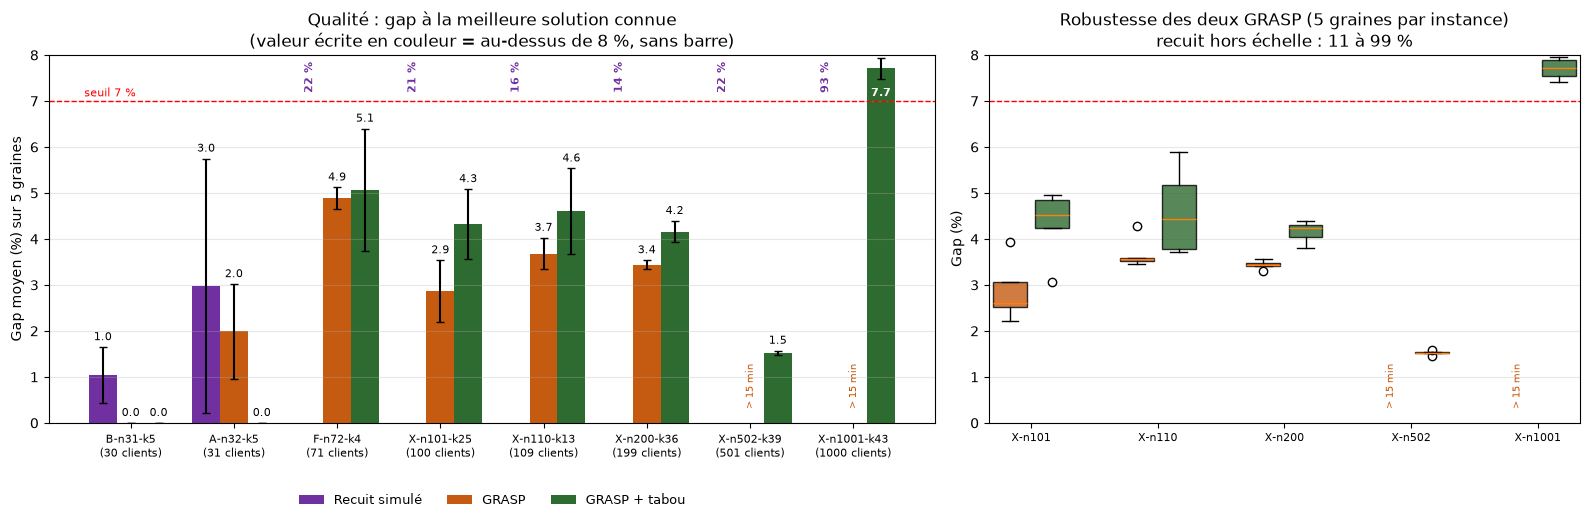

In [ ]:
dessiner(resultats, "images/comparatif_3_methodes.png");

**Ce que montrent les résultats**

- **Petites instances (30 clients)** : les trois méthodes sont bonnes (gap de 0 à 3 %). Le GRASP + tabou retrouve la meilleure solution connue à chaque graine.
- **Instances de 71 à 1 000 clients** : le **recuit simulé décroche** (14 à 22 % de gap en moyenne, 93 % à 1 000 clients). Les deux GRASP restent **sous le seuil de 7 %**, sauf le GRASP + tabou à 1 000 clients (7,7 %).
- **GRASP contre GRASP + tabou** : sur ces instances CVRP, le GRASP a un gap un peu plus petit (2,9 % contre 4,3 % sur X-n101-k25), mais son temps de calcul explose (environ 250 s à 199 clients, plus de 15 min à 501 clients), alors que le GRASP + tabou reste à 20 s jusqu'à 1 000 clients. Le GRASP + tabou est aussi le seul des trois qui gère les créneaux horaires.
- **Le gap ne grandit pas forcément avec la taille** : le GRASP + tabou fait 4,2 % sur X-n200 mais 1,5 % sur X-n502 (écart-type de 0,05). Sur X-n502, chaque client commande exactement 1 unité : échanger deux clients ne change jamais la charge des camions, les mouvements sont plus libres. Sur X-n200, les commandes sont variées et les camions pleins à 98,6 % : beaucoup de mouvements sont interdits par la capacité.
- **Limites** : les temps de calcul ne sont pas identiques (20 s pour le GRASP + tabou, arrêt par la température pour le recuit, 20 itérations pour le GRASP). Sur F-n72-k4, le GRASP utilise 5 camions au lieu de 4. Les 18 instances Solomon (avec créneaux) ne sont pas comparables ici.

**Conclusion** : le recuit simulé, avec un seul voisinage, ne passe pas à l'échelle en qualité. Le GRASP est précis sur le CVRP mais ne passe pas à l'échelle en temps. Le GRASP + tabou est le meilleur compromis, et le seul qui gère les créneaux : c'est la méthode retenue.

### 12.8 Bilan du déroulement

- Le problème a d'abord été **modélisé** (PLNE) avant d'être codé : cela a donné une solution exacte de référence pour vérifier les métaheuristiques sur les petites instances.
- Les mesures ont guidé les choix : le recuit a été écarté sur des chiffres, le GRASP a été corrigé grâce au gap, et les accélérations viennent de l'étude de passage à l'échelle.
- À faire autrement : mettre le code sur GitHub dès le premier jour (pour garder l'historique), et fixer plus tôt une façon commune de lancer les tests, pour comparer les méthodes avec le même temps de calcul.

## Références

- Dantzig, G. B. et Ramser, J. H. (1959). The truck dispatching problem. *Management Science*, 6(1), 80-91.
- Karp, R. M. (1972). Reducibility among combinatorial problems. *Complexity of Computer Computations*, 85-103.
- Savelsbergh, M. W. P. (1985). Local search in routing problems with time windows. *Annals of Operations Research*, 4, 285-305.
- Glover, F. (1986). Future paths for integer programming and links to artificial intelligence. *Computers & Operations Research*, 13(5), 533-549.
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254-265.
- Feo, T. A. et Resende, M. G. C. (1995). Greedy randomized adaptive search procedures. *Journal of Global Optimization*, 6, 109-133.
- Toth, P. et Vigo, D. (dir.) (2014). *Vehicle Routing: Problems, Methods, and Applications* (2e éd.). SIAM.
- Uchoa, E. et al. (2017). New benchmark instances for the Capacitated Vehicle Routing Problem. *European Journal of Operational Research*, 257(3), 845-858.
- Arnold, F., Gendreau, M. et Sörensen, K. (2019). Efficiently solving very large-scale routing problems. *Computers & Operations Research*, 107, 32-42.
- Instances et bibliothèque : [CVRPLIB / PyVRP Instances](https://github.com/PyVRP/Instances), [vrplib](https://github.com/PyVRP/VRPLIB).